# Домашнее задание 1. Свёртки, обучение глубоких сетей, adversarial robustness

**Дедлайн:** ДД.ММ.2026, 23:59 (3 недели).

- Заполняйте места с `# ваш код` и ячейки «Ответ». Сигнатуры, cell metadata и открытые тесты сохраняйте; можно добавлять свои ячейки. Открытые тесты проверяют часть контракта, при оценке будут и другие входы в пределах условия.
- После вопроса приведите наблюдение с числами, объяснение и, если нужно, ограничение вывода. Обычно хватает 2–4 предложений; для составного вопроса можно ответить по пунктам. Отсутствие ожидаемого эффекта — допустимый результат, если эксперимент корректен и вы это обсудили.
- Разделы 1–4, 5.1 и 6 обязательны. В разделе 5 выберите **одну** задачу: 5.2 targeted или 5.3 transfer (`ATTACK_TRACK`). Обе дают по 2 балла; вторая ветка не добавляет баллы. Бонусы 7.1–7.5 выбираются отдельно через `BONUS_TASKS`; за бонусы суммарно можно получить до 4 баллов из 5 предложенных.
- `FAST_MODE = True` — проверка кода на небольшом бюджете; финальные эксперименты делаются с `False`. Не выбранная ветка и выключенные бонусы автоматически пропускаются, даже если их решения пустые.
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs, приложить каталог `artifacts`, который создаётся перед бонусами. Если сдаёте частичное решение, перечислите нерешённые задачи в ячейке ниже и приложите доступные результаты; ошибки и отсутствие зависимых результатов не скрывайте. Для частичной сдачи успешный Run All и полный каталог artifacts не требуются. Баллы выставляются по отдельным критериям, одна ошибка не обнуляет остальные задачи.
- Для CIFAR-10 рекомендуется CUDA GPU с 8 GB памяти или больше; подойдёт Colab T4. FashionMNIST тоже удобно считать на GPU: adversarial training и серии PGD могут занимать десятки минут и дольше на CPU. Реальное время зависит от устройства; замеряйте его в своих прогонах. Бонусы не входят в основной бюджет.
- Можно пользоваться документацией PyTorch и материалами курса. Нельзя вызывать готовую реализацию того, что просят написать (`torch.optim.AdamW` внутри `MyAdamW`, `nn.BatchNorm2d` внутри `MyBatchNorm2d` и т.п.). Повторно использовать код семинаров можно, указав источник.
- В обучающих моделях используйте библиотечные `nn.Conv2d` и `nn.BatchNorm2d`; собственные слои из разделов 1–2 проверяются отдельно. В `train_cifar` нужен ваш `MyAdamW`.

| раздел | задачи | баллы |
|---|---|---|
| 1. Свёртка изнутри | 1.1 `unfold` · 1.2 backward · 1.3 RF и effective RF | 3.5 |
| 2. Нормализация | 2.1 `BatchNorm2d` · 2.2 Conv–BN fusion | 2 |
| 3. Инициализация и optimizer | 3.1 масштаб активаций · 3.2 `AdamW` · 3.3 cosine schedule | 3 |
| 4. ResNet на CIFAR-10 | 4.1 архитектура · 4.2 обучение · 4.3 plain-20 vs plain-56 | 4.5 |
| 5. Атаки | 5.1 PGD-$L_2$ и **одна** из 5.2 / 5.3 | 3 |
| 6. Adversarial training | 6.1 PGD-AT · 6.2 диагностика · 6.3 input gradients | 4 |
| 7*. Бонусы | 7.1 edge of stability · 7.2 FFT · 7.3 Muon · 7.4 $L_0$ · 7.5 catastrophic overfitting | до +4 |
| итого | | 20 + 4 |

Внутри задачи отдельно оцениваются код, эксперимент и объяснение; разбивка указана у каждого задания. Для вычислительного эксперимента нужны корректный протокол и сохранённые результаты, для объяснения — опора на ваши числа и понимание ограничений. Конкретная accuracy и совпадение с «ожидаемой картинкой» сами по себе не являются критерием балла.

Примерный порядок на три недели: первая — разделы 1–3; вторая — CIFAR-10 и выбранная задача об атаках; третья — adversarial training, анализ результатов и финальный прогон.

**Сведения о сдаче.** Устройство: MacBook Pro 16" (ноябрь 2023), чип Apple M3 Max, 64 ГБ памяти; вычисления на GPU через backend MPS (PyTorch 2.11.0, Python 3.13.2, CUDA недоступна). Выбранная ветка: 5.2 (targeted); ветка 5.3 не выполнялась. Выполнены бонусы 7.2, 7.4, 7.5 (BONUS_TASKS = {'7.2', '7.4', '7.5'}); бонусы 7.1 и 7.3 не выполнялись. Все обязательные разделы выполнены с FAST_MODE = False (Restart & Run All), результаты сохранены в папке artifacts. Внешние источники: документация PyTorch и материалы курса. Нерешённых обязательных задач нет.

In [1]:
# При необходимости, в отдельном окружении: %pip install -r requirements.txt
import copy
import itertools
import json
import math
from pathlib import Path
import time
import timeit

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import gradcheck
from torchvision import datasets

plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 12

print(f'PyTorch version: {torch.__version__}')
print(f'CUDA available:  {torch.cuda.is_available()}')
print(f'MPS available:   {torch.backends.mps.is_available()}')

PyTorch version: 2.11.0
CUDA available:  False
MPS available:   True


In [2]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    torch.manual_seed(seed)
    np.random.seed(seed)


device = get_device()
set_seed(0)
device

device(type='mps')

In [3]:
FAST_MODE = False   # True — отладка, False — финальный прогон
DATA_ROOT = './data'
ATTACK_TRACK = 'targeted'   # 'targeted' (5.2) или 'transfer' (5.3)
BONUS_TASKS = {'7.2', '7.4', '7.5'}        # например {'7.2', '7.4'}; пустое множество отключает все бонусы
assert ATTACK_TRACK in {'targeted', 'transfer'}
assert BONUS_TASKS <= {'7.1', '7.2', '7.3', '7.4', '7.5'}
RUN_TIMES = {}

Общие функции для разделов 4–7: данные лежат одним тензором на `device`, батчи режутся индексами (без `DataLoader` — так быстрее для маленьких картинок).

In [4]:
def iterate_batches(X, Y, batch_size, shuffle=True, transform=None):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for start in range(0, len(X), batch_size):
        b = idx[start:start + batch_size]
        yield (X[b] if transform is None else transform(X[b])), Y[b]


@torch.no_grad()
def predict_logits(model, X, batch_size=1000, transform=None):
    model.eval()
    return torch.cat([model(X[i:i + batch_size] if transform is None else transform(X[i:i + batch_size]))
                      for i in range(0, len(X), batch_size)])


def accuracy(logits, Y):
    return (logits.argmax(dim=1) == Y).float().mean().item()


def n_params(model):
    return sum(p.numel() for p in model.parameters())

---
# 1. Свёртка изнутри

## 1.1 `conv2d` через `unfold` (1 балл)

`F.unfold` (im2col) вырезает все патчи, которые видит ядро, и кладёт каждый патч столбцом:
$$
\mathrm{cols}[b,\, (c, u, v),\, \ell] = x_{\mathrm{pad}}\big[b,\, c,\; s\, i_\ell + d\, u,\; s\, j_\ell + d\, v\big], \qquad
\mathrm{cols} \in \mathbb R^{B \times C_{\text{in}} k_h k_w \times L}, \quad L = H_{\text{out}} W_{\text{out}},
$$
где $(i_\ell, j_\ell)$ — позиция $\ell$-го выхода. После этого свёртка — одно матричное умножение:
$$
y[b, o, \ell] = \sum_{(c, u, v)} W[o, (c, u, v)]\; \mathrm{cols}[b, (c, u, v), \ell] + \mathrm{bias}[o].
$$
С `groups = g` каналы делятся на $g$ групп: строки $\mathrm{cols}$ разбиваются на $g$ блоков по $\frac{C_{\text{in}}}{g} k_h k_w$, веса — на $g$ блоков по $\frac{C_{\text{out}}}{g}$ выходов, и каждая группа умножается только на свой блок.

Реализуйте `conv2d_unfold` для 4D-входа: stride, padding и dilation — целые числа или пары, groups — положительное целое, bias может быть `None`. Строковые padding и complex dtype не требуются. Циклов по батчу, каналам и позициям быть не должно.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [5]:
def pair(v):
    return v if isinstance(v, tuple) else (v, v)


def conv_output_size(size, kernel_size, stride=1, padding=0, dilation=1):
    return (size + 2 * padding - dilation * (kernel_size - 1) - 1) // stride + 1


def conv_output_shape(hw, kernel_size, stride=1, padding=0, dilation=1):
    params = zip(hw, pair(kernel_size), pair(stride), pair(padding), pair(dilation))
    return tuple(conv_output_size(*p) for p in params)

In [ ]:
def conv2d_unfold(x, weight, bias=None, stride=1, padding=0, dilation=1, groups=1):
    # x: (B, C_in, H, W), weight: (C_out, C_in / groups, kh, kw) -> (B, C_out, H_out, W_out)
    B, C_in, H, W = x.shape
    C_out, _, kh, kw = weight.shape
    H_out, W_out = conv_output_shape((H, W), (kh, kw), stride, padding, dilation)
    # вырезаем все положения ядра:
    cols = F.unfold(x, (kh, kw), dilation=dilation, padding=padding, stride=stride)
    # делим на группы
    cols = cols.reshape(B, groups, (C_in // groups) * kh * kw, H_out * W_out)
    w = weight.reshape(groups, C_out // groups, (C_in // groups) * kh * kw)
    # умножаем веса на столбики внутри каждой группы
    y = torch.einsum('gok,bgkl->bgol', w, cols).reshape(B, C_out, H_out * W_out)
    # добавляем bias
    if bias is not None:
        y = y + bias[None, :, None]
    return y.reshape(B, C_out, H_out, W_out)

In [7]:
torch.manual_seed(0)
x = torch.randn(2, 6, 11, 14)
n_checked = 0
for k, s, p, d, g in itertools.product([1, 3, (3, 5)], [1, 2, (2, 1)], [0, 1, (2, 1)], [1, 2], [1, 2, 3, 6]):
    if min(conv_output_shape((11, 14), k, s, p, d)) <= 0:
        continue
    w, b = torch.randn(12, 6 // g, *pair(k)), torch.randn(12)
    ref = F.conv2d(x, w, b, stride=s, padding=p, dilation=d, groups=g)
    assert torch.allclose(conv2d_unfold(x, w, b, s, p, d, g), ref, atol=1e-4), (k, s, p, d, g)
    assert torch.allclose(conv2d_unfold(x, w, None, s, p, d, g), ref - b[None, :, None, None], atol=1e-4)
    n_checked += 1
n_checked

216

**Вопрос.** Во сколько раз `cols` больше входа $x$ при $k = 3, 5, 7$ и `padding = k // 2`? Как стоимость im2col по памяти соотносится с тем, что FFT-свёртка выигрывает именно на больших ядрах?

In [8]:
x = torch.randn(8, 64, 32, 32)
for k in [3, 5, 7]:
    print(f'k = {k}: cols / x = {F.unfold(x, k, padding=k // 2).numel() / x.numel():.1f}')

k = 3: cols / x = 9.0
k = 5: cols / x = 25.0
k = 7: cols / x = 49.0


cols больше входа ровно в $k^2$ раз: 9, 25 и 49 при $k = 3, 5, 7$. Каждый пиксель входа копируется в $k^2$ столбцов, поэтому память im2col растёт как $O(k^2)$

FFT-свёртка не размножает данные в $k^2$ раз, и её стоимость почти не зависит от $k$. Поэтому она выигрывает именно на больших ядрах

## 1.2 Backward свёртки руками (1.5 балла)

Свёртка линейна по входу: $\mathrm{vec}(y) = M\, \mathrm{vec}(x) + b$ с разреженной матрицей $M$, в строках которой стоят веса ядра. Для $g = \partial L / \partial y$:
$$
\frac{\partial L}{\partial x} = M^\top g = \texttt{conv\_transpose2d}(g, W), \qquad
\frac{\partial L}{\partial W}[o, (c,u,v)] = \sum_{b,\ell} g[b, o, \ell]\; \mathrm{cols}[b, (c,u,v), \ell], \qquad
\frac{\partial L}{\partial b}[o] = \sum_{b, i, j} g[b, o, i, j].
$$
При stride $s > 1$ разные $H$ дают одинаковый $H_{\text{out}}$, и `conv_transpose2d` не знает, какой размер восстанавливать: нужную форму выбирает `output_padding`
$$
\mathrm{op}_H = H - \big((H_{\text{out}} - 1)s - 2p + k_h\big).
$$

Допишите `backward` (stride и padding — целые числа, dilation = 1, groups = 1). Проверка — `gradcheck` в float64 на размерах, где `output_padding` не равен нулю.

**Оценивание:** код — 1.2; эксперимент — 0; объяснение — 0.3 балла.

In [9]:
class Conv2dFunction(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, weight, bias, stride, padding):
        ctx.save_for_backward(x, weight)
        ctx.stride, ctx.padding = stride, padding
        return F.conv2d(x, weight, bias, stride=stride, padding=padding)

    @staticmethod
    def backward(ctx, grad_out):
        x, weight = ctx.saved_tensors
        s, p = ctx.stride, ctx.padding
        kh, kw = weight.shape[2:]
        grad_x = grad_w = grad_b = None
        if ctx.needs_input_grad[0]:
            H, W = x.shape[2:]
            H_out, W_out = grad_out.shape[2:]
            op_h = H - ((H_out - 1) * s - 2 * p + kh)
            op_w = W - ((W_out - 1) * s - 2 * p + kw)
            grad_x = F.conv_transpose2d(grad_out, weight, stride=s, padding=p, output_padding=(op_h, op_w))
        if ctx.needs_input_grad[1]:
            cols = F.unfold(x, (kh, kw), padding=p, stride=s)
            g = grad_out.flatten(2)
            grad_w = torch.einsum('bol,bkl->ok', g, cols).reshape(weight.shape)
        if ctx.needs_input_grad[2]:
            grad_b = grad_out.sum(dim=(0, 2, 3))
        return grad_x, grad_w, grad_b, None, None

In [10]:
torch.manual_seed(0)
n_checked = 0
for s, p, (H, W) in itertools.product([1, 2, 3], [0, 1, 2], [(7, 7), (8, 9), (10, 6)]):
    x = torch.randn(2, 3, H, W, dtype=torch.float64, requires_grad=True)
    w = torch.randn(4, 3, 3, 3, dtype=torch.float64, requires_grad=True)
    b = torch.randn(4, dtype=torch.float64, requires_grad=True)
    assert gradcheck(lambda x, w, b: Conv2dFunction.apply(x, w, b, s, p), (x, w, b)), (s, p, H, W)
    n_checked += 1
n_checked

27

**Вопрос.** Приведите два размера $H$, для которых свёртка $3 \times 3$ со stride 2 и padding 1 даёт одинаковый $H_{\text{out}}$, и `output_padding` для каждого.

Для $k=3$, $s=2$, $p=1$ имеем $H_{\text{out}} = \lfloor (H-1)/2 \rfloor + 1$, поэтому $H = 7$ и $H = 8$ дают один и тот же $H_{\text{out}} = 4$

Тогда $(H_{\text{out}}-1)s - 2p + k_h = 7$ и $\mathrm{op}_H = H - 7$: для $H = 7$ output_padding = 0, для $H = 8$ output_padding = 1

## 1.3 Receptive field через autograd (1 балл)

Теоретический receptive field (RF) нейрона — область входа, потенциально влияющая на него по архитектуре. Носитель градиента на конкретном входе может быть меньше из-за ReLU, MaxPool или взаимных сокращений. Размер bounding box теоретического RF вдали от границ даёт рекурсия (функция `receptive_field` ниже) по слоям с ядром $k_l$, stride $s_l$ и dilation $d_l$:
$$
k_l^{\mathrm{eff}} = 1 + d_l (k_l - 1), \qquad r_0 = j_0 = 1, \qquad r_l = r_{l-1} + (k_l^{\mathrm{eff}} - 1)\, j_{l-1}, \qquad j_l = j_{l-1}\, s_l,
$$
$j_l$ — расстояние между соседними нейронами слоя $l$ в пикселях входа. Pooling считается так же.

Сети для проверки — свёртки с усредняющими ядрами (все веса $1/k^2$, bias 0) и `AvgPool`, без нелинейностей.

Реализуйте `empirical_rf`: по градиенту суммы каналов центрального выхода по входу найти размер bounding box ненулевых пикселей по высоте и ширине.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [11]:
def receptive_field(layers):
    # layers: список dict(k, s=1, d=1); возвращает (r, j) после каждого слоя
    r, j = 1, 1
    history = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        r = r + (1 + d * (k - 1) - 1) * j
        j = j * s
        history.append((r, j))
    return history


def make_avg_net(layers, max_pool=False):
    modules = []
    for layer in layers:
        k, s, d = layer['k'], layer.get('s', 1), layer.get('d', 1)
        if layer.get('pool'):
            modules.append(nn.MaxPool2d(k, s) if max_pool else nn.AvgPool2d(k, s))
        else:
            conv = nn.Conv2d(1, 1, k, stride=s, dilation=d)
            nn.init.constant_(conv.weight, 1 / k ** 2)
            nn.init.zeros_(conv.bias)
            modules.append(conv)
    return nn.Sequential(*modules)


RF_ARCHS = {
    'conv3x3 x4': [dict(k=3)] * 4,
    'conv-pool':  [dict(k=3), dict(k=2, s=2, pool=True), dict(k=3), dict(k=2, s=2, pool=True), dict(k=3)],
    'strided':    [dict(k=5, s=2), dict(k=3, s=2), dict(k=3)],
    'dilated':    [dict(k=3, d=1), dict(k=3, d=2), dict(k=3, d=4)],
}

In [ ]:
def empirical_rf(model, in_channels=1, size=96):
    # -> (высота, ширина) bounding box пикселей входа, влияющих на центральный выход
    x = torch.randn(1, in_channels, size, size, requires_grad=True)
    y = model(x)
    ci, cj = y.shape[2] // 2, y.shape[3] // 2 # центральный выход
    grad, = torch.autograd.grad(y[0, :, ci, cj].sum(), x) # на какие пиксели он влияет
    nonzero = grad[0].abs().sum(dim=0) != 0 # где градиент не ноль
    rows = nonzero.any(dim=1).nonzero().flatten() # номера строк
    cols = nonzero.any(dim=0).nonzero().flatten() # номера столбцов
    return (rows.max() - rows.min() + 1).item(), (cols.max() - cols.min() + 1).item()

In [13]:
torch.manual_seed(0)
for name, layers in RF_ARCHS.items():
    r = receptive_field(layers)[-1][0]
    assert empirical_rf(make_avg_net(layers)) == (r, r), name
    print(f'{name:<12} r = {r:>3}   MaxPool instead of AvgPool: {empirical_rf(make_avg_net(layers, max_pool=True))}')

conv3x3 x4   r =   9   MaxPool instead of AvgPool: (9, 9)
conv-pool    r =  18   MaxPool instead of AvgPool: (18, 18)
strided      r =  17   MaxPool instead of AvgPool: (17, 17)
dilated      r =  15   MaxPool instead of AvgPool: (15, 15)


In [14]:
# насколько «заполнен» носитель градиента у conv-pool при AvgPool и MaxPool (20 случайных входов)
layers = RF_ARCHS['conv-pool']
for max_pool in (False, True):
    counts, full_box = [], 0
    for seed in range(20):
        torch.manual_seed(seed)
        net = make_avg_net(layers, max_pool=max_pool)
        x = torch.randn(1, 1, 96, 96, requires_grad=True)
        y = net(x)
        grad, = torch.autograd.grad(y[0, :, y.shape[2] // 2, y.shape[3] // 2].sum(), x)
        nz = grad[0, 0] != 0
        counts.append(nz.sum().item())
        rows, cols = nz.any(1).nonzero().flatten(), nz.any(0).nonzero().flatten()
        full_box += (rows.max() - rows.min() + 1, cols.max() - cols.min() + 1) == (18, 18)
    print(f'{"MaxPool" if max_pool else "AvgPool"}: ненулевых пикселей в среднем {np.mean(counts):.0f}, '
          f'bounding box 18x18 у {full_box} из 20 входов')

AvgPool: ненулевых пикселей в среднем 324, bounding box 18x18 у 20 из 20 входов
MaxPool: ненулевых пикселей в среднем 239, bounding box 18x18 у 8 из 20 входов


**Вопрос.** Почему для проверки взяты усредняющие ядра без нелинейностей? Что меняется с `MaxPool` и почему?

Усредняющие ядра без нелинейностей делают сеть линейной: градиент не зависит от входа, все веса положительны, сокращений нет, поэтому носитель градиента точно равен теоретическому RF ($r = 9, 18, 17, 15$ для четырёх архитектур). С нелинейностями носитель зависит от входа, а теоретический RF — лишь верхняя граница

С MaxPool (в архитектуре conv-pool) градиент идёт только в элемент-максимум каждого окна: ненулевых пикселей в среднем по 20 случайным входам 239 против 324 у AvgPool, а bounding box $18 \times 18$ получился лишь у 8 из 20 входов (против 20 из 20 у AvgPool)

В трёх остальных архитектурах пулингов нет, поэтому замена там ничего не меняет. Вывод опирается на 20 случайных входов одной архитектуры.

### Effective receptive field

Для рассматриваемых усредняющих сетей носитель градиента совпадает с теоретическим RF, но вклад пикселей неравномерный. Для стопки из $L$ усредняющих свёрток $3 \times 3$ карта $\partial y_{\text{center}} / \partial x$ — это $L$-кратная свёртка равномерного ядра, то есть распределение суммы $L$ независимых равномерных величин на $\{-1, 0, 1\}$ по каждой оси:
$$
\sigma_{\text{ERF}} = \sqrt{L \cdot \tfrac23}, \qquad r_L = 2L + 1.
$$
По ЦПТ профиль близок к гауссовскому, и эффективная ширина растёт как $\sqrt L$: [Understanding the Effective Receptive Field in Deep Convolutional Neural Networks](https://arxiv.org/pdf/1701.04128), Luo et al., 2016.

Реализуйте `erf_std`: $|\nabla_x y_{\text{center}}|$, усреднённый по `n_inputs` случайным входам и просуммированный по каналам, нормировать в распределение по строкам и вернуть его стандартное отклонение (в пикселях).

In [15]:
def erf_std(model, in_channels=1, size=96, n_inputs=1):
    total = 0
    for _ in range(n_inputs):
        x = torch.randn(1, in_channels, size, size, requires_grad=True)
        y = model(x)
        ci, cj = y.shape[2] // 2, y.shape[3] // 2
        grad, = torch.autograd.grad(y[0, :, ci, cj].sum(), x)
        total = total + grad[0].abs().sum(dim=0) # влияние каждого пикселя
    influence = total / n_inputs # среднее по входам
    profile = influence.sum(dim=0) # влияние по горизонтали
    profile = profile / profile.sum()
    pos = torch.arange(size, dtype=profile.dtype)
    mean = (profile * pos).sum()
    return torch.sqrt((profile * (pos - mean) ** 2).sum()).item() # разброс вокруг центра

In [16]:
for L in [1, 2, 4, 8, 16]:
    assert abs(erf_std(make_avg_net([dict(k=3)] * L)) - math.sqrt(2 * L / 3)) < 1e-3, L

Теперь обычная сеть: $L$ свёрток $3 \times 3$ по 16 каналов, ReLU, веса из $\mathcal N(0,\, 2 / \text{fan\_in})$, среднее по 16 входам.

In [17]:
def make_relu_net(L, width=16, seed=0):
    torch.manual_seed(seed)
    layers, c = [], 1
    for _ in range(L):
        conv = nn.Conv2d(c, width, 3)
        nn.init.kaiming_normal_(conv.weight, nonlinearity='relu')
        nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c = width
    return nn.Sequential(*layers)


depths = [1, 2, 4, 8, 16]
erf = {'theoretical RF / 2': [float(L) for L in depths],
       'ERF std, averaging kernels': [erf_std(make_avg_net([dict(k=3)] * L)) for L in depths],
       'ERF std, random ReLU net': [erf_std(make_relu_net(L), n_inputs=16) for L in depths]}
for name, values in erf.items():
    print(f'{name:<28}' + ''.join(f'{v:>7.2f}' for v in values))

theoretical RF / 2             1.00   2.00   4.00   8.00  16.00
ERF std, averaging kernels     0.82   1.15   1.63   2.31   3.27
ERF std, random ReLU net       0.80   1.31   2.04   3.07   4.45


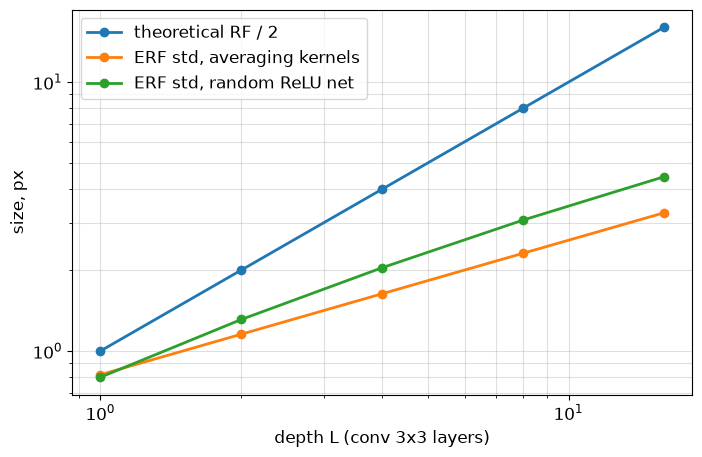

In [18]:
plt.figure(figsize=(8, 5))
for name, values in erf.items():
    plt.loglog(depths, values, 'o-', linewidth=2, label=name)
plt.xlabel('depth L (conv 3x3 layers)')
plt.ylabel('size, px')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Как отношение эффективного RF к теоретическому меняется с глубиной (наклоны на log-log графике)? Как ведёт себя сеть с ReLU по сравнению с усредняющей?

Теоретическая область растёт прямо пропорционально глубине (на графике наклон 1). Но реально сильно влияют только пиксели около центра, поэтому эффективная ширина растёт медленнее, примерно как $\sqrt{L}$ (наклон $\approx 0.5$): std 0.82, 1.15, 1.63, 2.31, 3.27 при $L = 1, 2, 4, 8, 16$. Значит, чем глубже сеть, тем меньшую часть теоретической области она реально использует (отношение падает как $1/\sqrt{L}$). У сети со случайными весами и ReLU std 0.80, 1.31, 2.04, 3.07, 4.45, наклон $\approx 0.62$: при $L \ge 2$ она шире усредняющей (на 36% при $L = 16$), но тоже растёт медленнее теоретической. Это один seed и усреднение по 16 входам, поэтому причину разницы между двумя сетями данные не доказывают.

---
# 2. Нормализация

## 2.1 `BatchNorm2d` с нуля (1 балл)

В `train()`: статистики текущего батча по каналу (среднее по $b, h, w$), нормировка смещённой дисперсией и обновление буферов
$$
\hat\mu \leftarrow (1 - m)\,\hat\mu + m\, \mu_{\text{batch}}, \qquad
\hat\sigma^2 \leftarrow (1 - m)\,\hat\sigma^2 + m\, \frac{n}{n - 1}\, \sigma^2_{\text{batch}}, \qquad n = BHW,
$$
в running-дисперсию идёт несмещённая оценка. В `eval()` — нормировка по $\hat\mu, \hat\sigma^2$. Параметры `weight` ($\gamma$) и `bias` ($\beta$), буферы `running_mean`, `running_var`, `num_batches_tracked` — с теми же именами, что в `nn.BatchNorm2d`, чтобы `load_state_dict` был совместим.

**Оценивание:** код — 0.8; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
class MyBatchNorm2d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps, self.momentum = eps, momentum
        self.weight = nn.Parameter(torch.ones(num_features)) # обучаемый масштаб
        self.bias = nn.Parameter(torch.zeros(num_features)) # обучаемый сдвиг
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))
        self.register_buffer('num_batches_tracked', torch.tensor(0, dtype=torch.long))

    def forward(self, x):
        if self.training:
            n = x.numel() // x.shape[1] # сколько чисел в одном канале: B*H*W
            if n <= 1:
                raise ValueError('Expected more than 1 value per channel when training')
            mean = x.mean(dim=(0, 2, 3))
            var = x.var(dim=(0, 2, 3), unbiased=False) # смещённая дисперсия для нормировки
            with torch.no_grad(): # обновляем память
                m = self.momentum
                self.running_mean.mul_(1 - m).add_(mean.detach(), alpha=m)
                self.running_var.mul_(1 - m).add_(var.detach() * n / (n - 1), alpha=m) # несмещённая
                self.num_batches_tracked += 1
        else:
            mean, var = self.running_mean, self.running_var
        x_hat = (x - mean[None, :, None, None]) / torch.sqrt(var[None, :, None, None] + self.eps)
        return x_hat * self.weight[None, :, None, None] + self.bias[None, :, None, None]

In [20]:
torch.manual_seed(0)
mine, ref = MyBatchNorm2d(8), nn.BatchNorm2d(8)
assert set(dict(mine.named_parameters())) == {'weight', 'bias'}
assert set(dict(mine.named_buffers())) == {'running_mean', 'running_var', 'num_batches_tracked'}
with torch.no_grad():
    for m in (mine, ref):
        m.weight.copy_(torch.linspace(0.5, 2, 8))
        m.bias.copy_(torch.linspace(-1, 1, 8))

for step in range(10):
    x = (torch.randn(4, 8, 5, 5) * 3 + 2).requires_grad_(True)
    out_mine, out_ref = mine(x), ref(x)
    assert torch.allclose(out_mine, out_ref, atol=1e-5), step
    g = torch.randn_like(out_ref)
    grads_mine = torch.autograd.grad(out_mine, (x, mine.weight, mine.bias), g)
    grads_ref = torch.autograd.grad(out_ref, (x, ref.weight, ref.bias), g)
    assert all(torch.allclose(a, b, atol=1e-4) for a, b in zip(grads_mine, grads_ref)), step

for name, buf in ref.named_buffers():
    assert torch.allclose(getattr(mine, name).float(), buf.float(), atol=1e-5), name

mine.eval(), ref.eval()
x = torch.randn(4, 8, 5, 5)
assert torch.allclose(mine(x), ref(x), atol=1e-5)
mine.load_state_dict(ref.state_dict())

<All keys matched successfully>

**Вопрос.** Почему в running-дисперсию идёт несмещённая оценка, а в нормировку батча — смещённая? Насколько они различаются при $B = 4$ и карте $5 \times 5$, и при $B = 2$ и карте $1 \times 1$?

Для нормировки текущего батча берётся смещённая дисперсия так как мы нормируем именно эти числа, и после этого их дисперсия ровно 1. В running-буфер идёт несмещённая оценка: он нужен, чтобы потом нормировать новые данные, а по небольшой выборке дисперсия получается слегка заниженной (в $(n-1)/n$ раз), поэтому её исправляют множителем $n/(n-1)$

Разница: при $B = 4$ и карте $5 \times 5$ ($n = 100$) множитель равен 1.0101, то есть 1%; при $B = 2$ и карте $1 \times 1$ ($n = 2$) — ровно 2 раза (std — в $\sqrt 2 \approx 1.41$ раза). Значит, на очень маленьких батчах разница заметна

## 2.2 Слияние свёртки и BatchNorm для инференса (1 балл)

В `eval()` BN — поканальное аффинное преобразование с фиксированными $\hat\mu, \hat\sigma^2$, поэтому $\mathrm{BN}(\mathrm{conv}(x))$ — снова свёртка с другими весами $W'$ и bias $b'$.

1. Выведите $W'$ и $b'$ в ячейке «Ответ» ниже.
2. Реализуйте `fuse_conv_bn(conv, bn)`, возвращающую новую `nn.Conv2d`: сохраняются `dtype`, `device`, `padding_mode`, `groups`, stride, padding и dilation; bias у исходной свёртки может отсутствовать. Входные модули в `eval()`, BN с affine и running statistics; исходные веса не менять.
3. Реализуйте `fuse_sequential(seq)` для плоского `nn.Sequential` в `eval()`: каждую соседнюю пару `Conv2d, BatchNorm2d` заменить свёрткой. Остальные модули скопировать через `copy.deepcopy`, исходную сеть не менять; рекурсивный обход вложенных контейнеров не требуется.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

Для выходного канала $o$ при фиксированных $\hat\mu_o$, $\hat\sigma_o^2$ и $s_o = \gamma_o / \sqrt{\hat\sigma_o^2 + \varepsilon}$:
$$\mathrm{BN}(\mathrm{conv}(x))_o = s_o \big(W_o * x + b_o - \hat\mu_o\big) + \beta_o = (s_o W_o) * x + \big[(b_o - \hat\mu_o)\, s_o + \beta_o\big].$$
Поэтому
$$W'_o = \frac{\gamma_o}{\sqrt{\hat\sigma_o^2 + \varepsilon}}\, W_o, \qquad b'_o = \frac{\gamma_o\,(b_o - \hat\mu_o)}{\sqrt{\hat\sigma_o^2 + \varepsilon}} + \beta_o,$$
а если у свёртки нет bias, то $b_o = 0$.


In [ ]:
from collections import OrderedDict


@torch.no_grad()
def fuse_conv_bn(conv, bn):
    scale = bn.weight / torch.sqrt(bn.running_var + bn.eps)
    fused = nn.Conv2d(conv.in_channels, conv.out_channels, conv.kernel_size,
                      stride=conv.stride, padding=conv.padding, dilation=conv.dilation,
                      groups=conv.groups, bias=True, padding_mode=conv.padding_mode,
                      device=conv.weight.device, dtype=conv.weight.dtype)
    fused.weight.copy_(conv.weight * scale[:, None, None, None])
    conv_bias = conv.bias if conv.bias is not None else torch.zeros_like(bn.running_mean)
    fused.bias.copy_((conv_bias - bn.running_mean) * scale + bn.bias) 
    return fused.train(conv.training)


def fuse_sequential(seq):
    layers = list(seq.named_children())
    out, i = [], 0
    while i < len(layers):
        name, layer = layers[i]
        if (isinstance(layer, nn.Conv2d) and i + 1 < len(layers)
                and isinstance(layers[i + 1][1], nn.BatchNorm2d)):
            out.append((name, fuse_conv_bn(layer, layers[i + 1][1])))
            i += 2
        else:
            out.append((name, copy.deepcopy(layer)))
            i += 1
    return nn.Sequential(OrderedDict(out)).train(seq.training)

In [22]:
torch.manual_seed(0)
for cfg in [dict(bias=True), dict(bias=False), dict(groups=4), dict(stride=2, padding=1, dilation=2)]:
    conv, bn = nn.Conv2d(8, 16, 3, **cfg), nn.BatchNorm2d(16)
    with torch.no_grad():
        bn.weight.uniform_(0.5, 2)
        bn.bias.uniform_(-1, 1)
        for _ in range(5):
            bn(conv(torch.randn(8, 8, 12, 12) * 2 + 1))   # накопить running-статистики
    conv.eval(), bn.eval()
    x = torch.randn(4, 8, 12, 12)
    fused = fuse_conv_bn(conv, bn)
    assert isinstance(fused, nn.Conv2d)
    assert torch.allclose(fused(x), bn(conv(x)), atol=1e-5), cfg

conv = nn.Conv2d(4, 8, 3, padding=1, padding_mode='reflect', groups=2, bias=False).double().eval()
bn = nn.BatchNorm2d(8).double().eval()
x = torch.randn(2, 4, 9, 11, dtype=torch.float64)
fused = fuse_conv_bn(conv, bn)
assert fused.weight.dtype == x.dtype and fused.padding_mode == 'reflect'
assert torch.allclose(fused(x), bn(conv(x)), atol=1e-10, rtol=1e-10)

In [23]:
def make_vgg_like(width=64, n_blocks=6):
    layers, c = [], 3
    for i in range(n_blocks):
        layers += [nn.Conv2d(c, width, 3, padding=1, bias=False), nn.BatchNorm2d(width), nn.ReLU()]
        c = width
        if i % 2 == 1:
            layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers, nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10))


torch.manual_seed(0)
vgg = make_vgg_like()
with torch.no_grad():
    for _ in range(5):
        vgg(torch.randn(32, 3, 32, 32))   # train-режим: копим статистики
vgg.eval()
vgg_fused = fuse_sequential(vgg).eval()
x = torch.randn(64, 3, 32, 32)
assert not any(isinstance(m, nn.BatchNorm2d) for m in vgg_fused.modules())
assert torch.allclose(vgg(x), vgg_fused(x), atol=1e-4)

In [24]:
with torch.inference_mode():
    t_bn = min(timeit.repeat(lambda: vgg(x), number=5, repeat=5)) / 5
    t_fused = min(timeit.repeat(lambda: vgg_fused(x), number=5, repeat=5)) / 5
print(f'Conv + BN: {t_bn * 1000:.1f} ms   fused: {t_fused * 1000:.1f} ms   speedup {t_bn / t_fused:.2f}x')

Conv + BN: 80.1 ms   fused: 79.9 ms   speedup 1.00x


**Вопрос.** Почему слияние корректно только в `eval()`? Что даёт слияние и от чего зависит выигрыш?

В train() BN нормирует по статистикам текущего батча: это зависит от самого батча и меняется от батча к батчу, ещё и обновляет буферы, поэтому заменить её фиксированными весами нельзя. В eval() статистики зафиксированы, BN становится простым поканальным «умножить и прибавить», и свёртка может это поглотить (расхождение с исходной сетью в тестах в пределах $10^{-4}$ для float32). Слияние убирает отдельный проход по памяти и лишние параметры. Выигрыш зависит от того, какую долю времени занимает BN: он заметен там, где BN ограничен памятью (GPU, небольшие свёртки, мобильные устройства), и почти незаметен, если время определяют сами свёртки. В моём прогоне Conv+BN занял 80.1 мс, fused — 79.9 мс, то есть ускорение 1.00×: на этом устройстве время почти целиком уходит на сами свёртки, поэтому выигрыш практически отсутствует.

---
# 3. Инициализация и оптимизатор

## 3.1 Дисперсия активаций по глубине (1 балл)

Слой $h = W z$, $W_{ij}$ независимы, $\mathbb E W_{ij} = 0$, $\mathrm{Var}\, W_{ij} = v$, $W$ не зависит от $z \in \mathbb R^{n}$:
$$
\mathrm{Var}(h_i) = n\, v\; \mathbb E\big[z_j^2\big].
$$

1. В ячейке «Ответ» ниже выведите $v$, при котором $\mathrm{Var}(h)$ не меняется от слоя к слою, для $z = \mathrm{ReLU}(h^{\text{prev}})$ с симметричным $h^{\text{prev}}$ и для $\tanh$ в линейном режиме. Инициализация `nn.Linear` по умолчанию — $\mathcal U(-1/\sqrt n,\, 1/\sqrt n)$: во сколько раз за слой меняется стандартное отклонение активаций для ReLU?
2. Реализуйте `activation_stds`: MLP глубины 50 и ширины 256 без bias, на входе $\mathcal N(0, I)$, вернуть `h.std().item()` после каждой активации — по **всем** элементам тензора `(n, width)`, а не среднее std по отдельным нейронам. Верните список из `depth` чисел.

**Оценивание:** код — 0.3; эксперимент — 0.3; объяснение — 0.4 балла.

Нужно, чтобы разброс не менялся от слоя к слою: $\mathrm{Var}(h) = \mathrm{Var}(h^{\text{prev}})$, то есть $n\,v\,\mathbb E[z^2] = \mathrm{Var}(h^{\text{prev}})$.

ReLU зануляет отрицательную половину значений, поэтому $\mathbb E[z^2] = \tfrac12 \mathrm{Var}(h^{\text{prev}})$. Тогда $n v \cdot \tfrac12 = 1$ и $v = 2/n$ (инициализация Kaiming).

tanh в линейном режиме: $\tanh(h) \approx h$, поэтому $\mathbb E[z^2] = \mathrm{Var}(h^{\text{prev}})$ и $v = 1/n$ (Xavier).

По умолчанию $W \sim \mathcal U(-1/\sqrt n,\, 1/\sqrt n)$, дисперсия $v = \dfrac{(2/\sqrt n)^2}{12} = \dfrac{1}{3n}$. Для ReLU дисперсия за слой умножается на $n \cdot \frac{1}{3n} \cdot \frac12 = \frac16$, то есть стандартное отклонение — в $1/\sqrt6 \approx 0.408$ раза за слой (в эксперименте 0.410). За 50 слоёв это примерно $3.5 \cdot 10^{-20}$.


In [ ]:
INITS = {
    'N(0, 0.01^2)': lambda w: nn.init.normal_(w, std=0.01),
    'PyTorch default': lambda w: nn.init.kaiming_uniform_(w, a=math.sqrt(5)),
    'Xavier': nn.init.xavier_normal_,
    'Kaiming': lambda w: nn.init.kaiming_normal_(w, nonlinearity='relu'),
}


def activation_stds(init, act, depth=50, width=256, n=1024, seed=0):
    torch.manual_seed(seed)
    h = torch.randn(n, width) # вход: случайные числа N(0, 1)
    stds = []
    with torch.no_grad():
        for _ in range(depth):
            layer = nn.Linear(width, width, bias=False) # слой без bias
            init(layer.weight) # применяем выбранную инициализацию
            h = act(layer(h)) # слой + активация
            stds.append(h.std().item()) # разброс по всем числам тензора
    return stds

In [26]:
stds = {(name, act_name): activation_stds(init, act)
        for name, init in INITS.items() for act_name, act in [('tanh', torch.tanh), ('ReLU', torch.relu)]}

kaiming_relu = stds['Kaiming', 'ReLU']
assert len(kaiming_relu) == 50 and np.isfinite(kaiming_relu).all()
print(f'Kaiming + ReLU, last / first std: {kaiming_relu[-1] / kaiming_relu[0]:.3f}')
default_relu = np.array(stds['PyTorch default', 'ReLU'])
rate = np.exp(np.mean(np.diff(np.log(default_relu))))   # средний множитель std за слой
assert abs(rate - 1 / math.sqrt(6)) < 0.03
rate

Kaiming + ReLU, last / first std: 0.882


np.float64(0.41000275007432835)

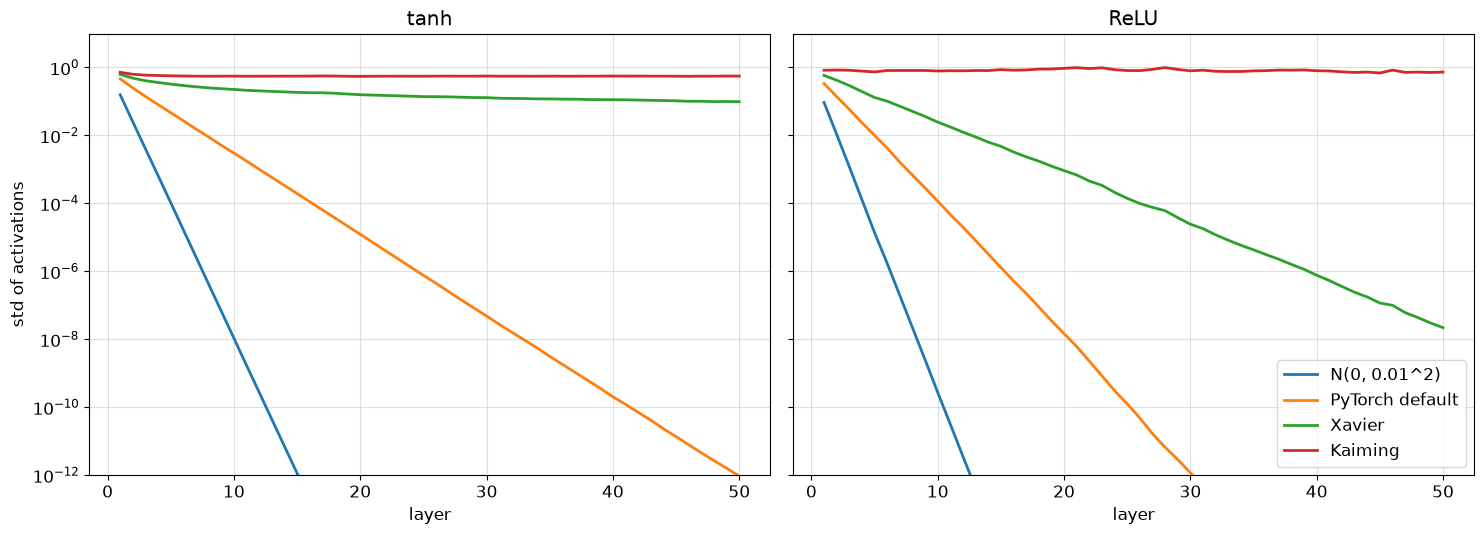

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, act_name in zip(axes, ['tanh', 'ReLU']):
    for name in INITS:
        ax.semilogy(range(1, 51), stds[name, act_name], linewidth=2, label=name)
    ax.set_title(act_name)
    ax.set_xlabel('layer')
    ax.grid(True, which='both', alpha=0.4)
axes[0].set_ylabel('std of activations')
axes[0].set_ylim(1e-12, 10)
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Какие пары (инициализация, активация) сохраняют масштаб на 50 слоях? Почему сети с инициализацией PyTorch по умолчанию всё равно обучаются (например, ResNet в задаче 4.2)?

Масштаб на 50 слоях сохраняют Kaiming+ReLU (std 0.83 → 0.73, в 0.88 раза) и Kaiming+tanh (0.72 → 0.56). Xavier+tanh затухает медленно (0.63 → 0.099). Остальные пары схлопываются почти в ноль: Xavier+ReLU до $2 \cdot 10^{-8}$, инициализация PyTorch по умолчанию с tanh до $9 \cdot 10^{-13}$ и с ReLU до $4 \cdot 10^{-20}$, $\mathcal N(0, 0.01^2)$ — до $10^{-40}$ с tanh и до нуля с ReLU.
ResNet с инициализацией по умолчанию всё равно обучается, потому что это не простой стек из 50 слоёв. После каждой свёртки стоит BatchNorm, который возвращает масштаб активаций к единице независимо от масштаба весов. Shortcut-связи дают сигналу и градиенту прямой путь через всю сеть. И глубина здесь всего 20 слоёв, а не 50.

## 3.2 `AdamW` своими руками (1.5 балла)

Шаг $t = 1, 2, \dots$; $\eta$ — learning rate, $\lambda$ — weight decay, $g_t$ — градиент:
$$
\theta \leftarrow \theta - \eta\lambda\,\theta, \qquad
m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t, \qquad
v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2,
$$
$$
\hat m_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat v_t = \frac{v_t}{1 - \beta_2^t}, \qquad
\theta \leftarrow \theta - \eta\, \frac{\hat m_t}{\sqrt{\hat v_t} + \epsilon}.
$$
Флаг `bias_correction=False` выключает деление на $1 - \beta^t$. Гиперпараметры берутся из `group` — у разных групп параметров они могут отличаться (в `train_cifar` из задачи 4.2 weight decay не применяется к параметрам BN и bias).

**Оценивание:** код — 1.1; эксперимент — 0.1; объяснение — 0.3 балла.

In [ ]:
class MyAdamW(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=1e-2, bias_correction=True):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay, bias_correction=bias_correction)
        super().__init__(params, defaults)

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            beta1, beta2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p) # m
                    state['exp_avg_sq'] = torch.zeros_like(p) # v
                state['step'] += 1
                t = state['step']
                lr, eps, wd = group['lr'], group['eps'], group['weight_decay']
                g = p.grad
                m, v = state['exp_avg'], state['exp_avg_sq']
                p.mul_(1 - lr * wd)
                m.mul_(beta1).add_(g, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(g, g, value=1 - beta2)
                if group['bias_correction']:
                    m_hat = m / (1 - beta1 ** t)
                    v_hat = v / (1 - beta2 ** t)
                else:
                    m_hat, v_hat = m, v
                p.sub_(lr * m_hat / (v_hat.sqrt() + eps))

In [29]:
def final_params(make_optimizer, steps=100):
    torch.manual_seed(0)
    model = nn.Sequential(nn.Linear(10, 32), nn.Tanh(), nn.Linear(32, 1))
    optimizer = make_optimizer(model)
    gen = torch.Generator().manual_seed(1)
    for _ in range(steps):
        x = torch.randn(64, 10, generator=gen)
        loss = F.mse_loss(model(x), x[:, :1] ** 2)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return torch.cat([p.detach().flatten() for p in model.parameters()])


def param_groups(model, wd):
    return [dict(params=[p for p in model.parameters() if p.ndim > 1], weight_decay=wd),
            dict(params=[p for p in model.parameters() if p.ndim <= 1], weight_decay=0.0, lr=3e-3)]


for kwargs in [dict(lr=1e-2), dict(lr=1e-2, weight_decay=0.1), dict(lr=3e-3, betas=(0.8, 0.9), eps=1e-1)]:
    mine = final_params(lambda m: MyAdamW(m.parameters(), **kwargs))
    ref = final_params(lambda m: torch.optim.AdamW(m.parameters(), **kwargs))
    assert torch.allclose(mine, ref, atol=1e-5), kwargs
mine = final_params(lambda m: MyAdamW(param_groups(m, 0.1), lr=1e-2))
ref = final_params(lambda m: torch.optim.AdamW(param_groups(m, 0.1), lr=1e-2))
assert torch.allclose(mine, ref, atol=1e-5)

Длина шага при постоянном градиенте $g = 1$:

In [30]:
def step_lengths(make_optimizer, steps=1000):
    p = torch.zeros(1, requires_grad=True)
    optimizer = make_optimizer([p])
    lengths = []
    for _ in range(steps):
        before = p.item()
        optimizer.zero_grad()
        p.sum().backward()
        optimizer.step()
        lengths.append(before - p.item())
    return np.array(lengths)


lr = 0.01
bc_runs = {bc: step_lengths(lambda ps: MyAdamW(ps, lr=lr, weight_decay=0, bias_correction=bc)) for bc in [True, False]}
for bc, lengths in bc_runs.items():
    ratio = np.round(lengths / lr, 4)
    print(f'bias_correction={bc!s:<5}  step / lr: ' + '  '.join(f't={t}: {ratio[t - 1]:.2f}' for t in [1, 10, 100, 1000])
          + f'   max {ratio.max():.2f} at t={ratio.argmax() + 1}')

bias_correction=True   step / lr: t=1: 1.00  t=10: 1.00  t=100: 1.00  t=1000: 1.00   max 1.00 at t=1
bias_correction=False  step / lr: t=1: 3.16  t=10: 6.53  t=100: 3.24  t=1000: 1.26   max 6.57 at t=12


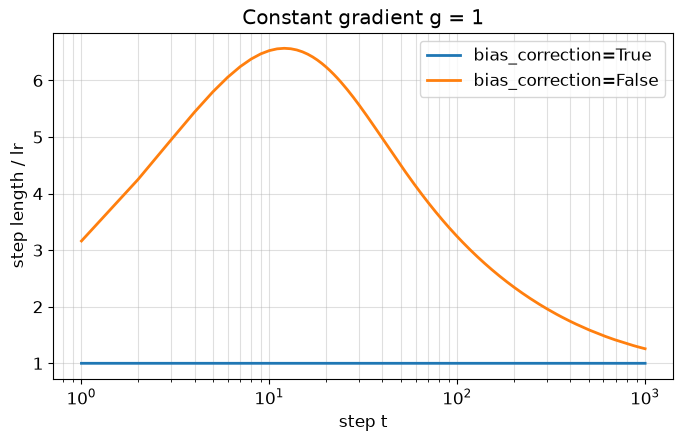

In [31]:
plt.figure(figsize=(8, 4.5))
for bc, lengths in bc_runs.items():
    plt.semilogx(range(1, len(lengths) + 1), lengths / lr, linewidth=2, label=f'bias_correction={bc}')
plt.xlabel('step t')
plt.ylabel('step length / lr')
plt.title('Constant gradient g = 1')
plt.legend()
plt.grid(True, which='both', alpha=0.4)
plt.show()

**Вопрос.** Выведите длину шага без bias correction при $g_t \equiv 1$ как функцию $t$ и сравните с выводом ячейки. Чем это опасно в начале обучения?

При постоянном градиенте $g_t \equiv 1$ имеем $m_t = 1 - \beta_1^t$ и $v_t = 1 - \beta_2^t$, поэтому длина шага без bias correction равна $\eta \cdot \dfrac{1 - \beta_1^t}{\sqrt{1 - \beta_2^t} + \epsilon}$. При $t = 1$ это $\eta \cdot 0.1 / \sqrt{0.001} \approx 3.16\,\eta$. Максимум $\approx 6.57\,\eta$ достигается при $t = 12$, потом шаг падает до $1.26\,\eta$ к $t = 1000$. Это совпадает с выводом ячейки (3.16; 6.53 при $t = 10$; 3.24 при $t = 100$; 1.26 при $t = 1000$; максимум 6.57 при $t = 12$) и с графиком. С bias correction шаг равен $\eta$ при любом $t$.

Опасность в начале обучения в том, что шаги в 3–6 раз больше заданного learning rate, пока $v$ ещё не накопилась. Это может раскачать или испортить стартовые веса, особенно при большом learning rate и без warmup.

## 3.3 Cosine schedule (0.5 балла)

Множитель learning rate для `LambdaLR` (шаг $t$ считается с нуля, $T$ — число шагов, $r$ — доля от начального lr в конце):
$$
\lambda(t) = r + (1 - r)\, \frac{1 + \cos\big(\pi \min(1,\, t / T)\big)}{2}.
$$
На интервале от нулевого шага до $T$ это то же расписание, что `CosineAnnealingLR(T_max=T, eta_min=r·lr)`; после $T$ наша функция остаётся на минимуме, в отличие от продолжения cosine в PyTorch; проверка — совпадение learning rate по шагам с вашим `MyAdamW`.

**Оценивание:** код — 0.3; эксперимент — 0; объяснение — 0.2 балла.

In [ ]:
def cosine_lr(step, total_steps, min_ratio=0.0):
    progress = min(1.0, step / total_steps)
    return min_ratio + (1 - min_ratio) * (1 + math.cos(math.pi * progress)) / 2

In [33]:
T, r, base_lr = 500, 0.1, 3e-3
lam = [cosine_lr(t, T, r) for t in range(T + 1)]
assert abs(lam[0] - 1) < 1e-12 and abs(lam[T] - r) < 1e-12 and abs(cosine_lr(2 * T, T, r) - r) < 1e-12
assert abs(lam[T // 2] - (r + (1 - r) / 2)) < 1e-9


def lr_trace(make_scheduler, steps=T):
    p = torch.zeros(1, requires_grad=True)
    optimizer = MyAdamW([p], lr=base_lr)
    scheduler = make_scheduler(optimizer)
    trace = []
    for _ in range(steps):
        trace.append(scheduler.get_last_lr()[0])
        optimizer.step()
        scheduler.step()
    return np.array(trace)


mine = lr_trace(lambda opt: torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_lr(t, T, r)))
ref = lr_trace(lambda opt: torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=T, eta_min=r * base_lr))
assert np.allclose(mine, ref, rtol=1e-6, atol=1e-12)

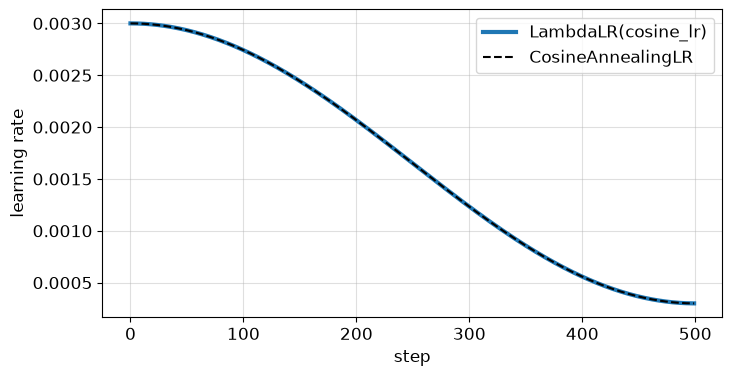

In [34]:
plt.figure(figsize=(8, 4))
plt.plot(mine, linewidth=3, label='LambdaLR(cosine_lr)')
plt.plot(ref, 'k--', linewidth=1.5, label='CosineAnnealingLR')
plt.xlabel('step')
plt.ylabel('learning rate')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Зачем уменьшать learning rate к концу обучения, если оптимизатор и так адаптивный? Что происходит со стохастическим методом при постоянном шаге около минимума?

Adam нормирует шаг на $\sqrt{\hat v}$, но его длина всё равно остаётся порядка $\eta$, а градиент по минибатчу шумный. Вблизи минимума знак $\hat m$ колеблется, и параметры «дрожат» в окрестности минимума размером порядка $\eta$: адаптивность шум не убирает. У стохастического метода с постоянным шагом то же самое: он не сходится в точку, а блуждает в шаре, размер которого растёт с шагом и с шумом градиента. Снижение learning rate к нулю (cosine) сужает эту окрестность и позволяет «осесть» в минимум, поэтому к концу обучения обычно падает train loss и стабилизируется test accuracy.

---
# 4. ResNet на CIFAR-10

CIFAR-10: 50 000 + 10 000 цветных картинок $32 \times 32$, 10 классов. Весь датасет хранится одним `uint8`-тензором на `device` (≈ 180 MB), нормализация делается на лету над батчем.

In [35]:
N_TRAIN = 10_000 if FAST_MODE else 50_000
N_TEST = 2_000 if FAST_MODE else 10_000

cifar_train = datasets.CIFAR10(DATA_ROOT, train=True, download=True)
cifar_test = datasets.CIFAR10(DATA_ROOT, train=False, download=True)
CIFAR_CLASSES = cifar_train.classes


def to_tensors(ds, n):
    X = torch.from_numpy(ds.data[:n]).permute(0, 3, 1, 2).contiguous()   # uint8 (N, 3, 32, 32)
    return X.to(device), torch.tensor(ds.targets[:n]).to(device)


X_train, Y_train = to_tensors(cifar_train, N_TRAIN)
X_test, Y_test = to_tensors(cifar_test, N_TEST)
CIFAR_MEAN = (X_train.float() / 255).mean(dim=(0, 2, 3))
CIFAR_STD = (X_train.float() / 255).std(dim=(0, 2, 3))
X_train.shape, X_test.shape, CIFAR_MEAN, CIFAR_STD

/Users/macbook/Downloads/hw1_students/.venv/lib/python3.13/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


(torch.Size([50000, 3, 32, 32]),
 torch.Size([10000, 3, 32, 32]),
 tensor([0.4914, 0.4822, 0.4465], device='mps:0'),
 tensor([0.2470, 0.2435, 0.2616], device='mps:0'))

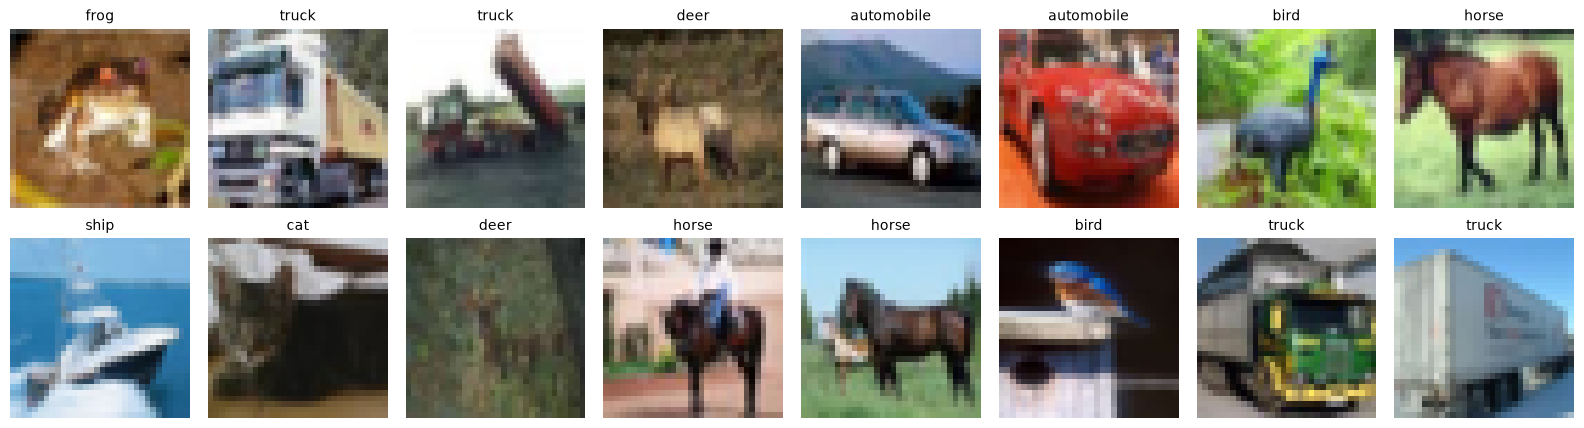

In [36]:
def normalize(x_uint8):
    return (x_uint8.float() / 255 - CIFAR_MEAN[:, None, None]) / CIFAR_STD[:, None, None]


fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, range(16)):
    ax.imshow(X_train[i].permute(1, 2, 0).cpu())
    ax.set_title(CIFAR_CLASSES[Y_train[i]], fontsize=10)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4.1 ResNet для CIFAR (1 балл)

ResNet для CIFAR из §4.2 статьи [Deep Residual Learning for Image Recognition](https://arxiv.org/pdf/1512.03385), He et al., 2015: stem — свёртка $3 \times 3$ на 16 каналов с BN и ReLU; затем три стадии по $n$ блоков шириной 16, 32 и 64; в конце global average pooling и `Linear(64, 10)`. Глубина $6n + 2$. Первый блок второй и третьей стадии — со stride 2.

Блок (свёртки $3 \times 3$ без bias):
$$
F(x) = \mathrm{BN}\Big(\mathrm{Conv}\big(\mathrm{ReLU}(\mathrm{BN}(\mathrm{Conv}(x)))\big)\Big), \qquad y = \mathrm{ReLU}\big(F(x) + \mathrm{shortcut}(x)\big).
$$
Shortcut — `Identity`, а при смене формы (stride 2 или другое число каналов) — свёртка $1 \times 1$ с тем же stride и BN после неё. Флаги:

- `residual=False` — plain-сеть: сложения нет, shortcut-модулей нет;
- `separable=True` — каждая $3 \times 3$ свёртка блоков заменена на depthwise $3 \times 3$ и следующую за ней pointwise $1 \times 1$, обе без bias; stem остаётся обычным.

**Оценивание:** код — 1; эксперимент — 0; объяснение — 0 балла.

In [ ]:
def conv3x3(c_in, c_out, stride=1, separable=False):
    if not separable:
        return nn.Conv2d(c_in, c_out, 3, stride=stride, padding=1, bias=False)
    return nn.Sequential(
        nn.Conv2d(c_in, c_in, 3, stride=stride, padding=1, groups=c_in, bias=False),
        nn.Conv2d(c_in, c_out, 1, bias=False))


class Block(nn.Module):
    def __init__(self, c_in, c_out, stride=1, residual=True, separable=False):
        super().__init__()
        self.residual = residual
        self.conv1 = conv3x3(c_in, c_out, stride, separable)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = conv3x3(c_out, c_out, 1, separable)
        self.bn2 = nn.BatchNorm2d(c_out)
        if residual:
            if stride != 1 or c_in != c_out
                self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride=stride, bias=False), nn.BatchNorm2d(c_out))
            else:
                self.shortcut = nn.Identity()

    def forward(self, x):
        out = self.bn2(self.conv2(F.relu(self.bn1(self.conv1(x))))) # F(x)
        if self.residual:
            out = out + self.shortcut(x)
        return F.relu(out)


class ResNetCIFAR(nn.Module):
    def __init__(self, depth=20, residual=True, separable=False, widths=(16, 32, 64), n_classes=10):
        super().__init__()
        assert (depth - 2) % 6 == 0
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, padding=1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        blocks, c_in = [], widths[0]
        for stage, width in enumerate(widths):
            for j in range(n):
                stride = 2 if (stage > 0 and j == 0) else 1
                blocks.append(Block(c_in, width, stride, residual, separable))
                c_in = width
        self.blocks = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        return self.fc(self.pool(x).flatten(1))

In [38]:
x = torch.randn(2, 3, 32, 32)
for depth in [8, 20, 56]:
    for kwargs in [dict(), dict(residual=False), dict(separable=True)]:
        assert ResNetCIFAR(depth, **kwargs)(x).shape == (2, 10), (depth, kwargs)
assert n_params(ResNetCIFAR(20)) == 272_474
assert n_params(ResNetCIFAR(20, residual=False)) == 269_722
{name: n_params(ResNetCIFAR(depth, **kwargs)) for name, depth, kwargs in
 [('ResNet-20', 20, {}), ('ResNet-56', 56, {}), ('ResNet-20, separable', 20, dict(separable=True))]}

{'ResNet-20': 272474, 'ResNet-56': 855770, 'ResNet-20, separable': 40522}

## 4.2 Обучение (2 балла)

Реализуйте `train_cifar`: `MyAdamW` из 3.2 (weight decay только для параметров с `ndim > 1`), `LambdaLR` с `cosine_lr` из 3.3 до нуля за всё обучение ($r = 0$), cross-entropy, батч 256. После каждой эпохи — test accuracy. Вернуть историю `dict(train_loss, test_acc)` по эпохам.

Для ResNet-20 при `FAST_MODE = False` ориентир test accuracy — `TARGET_ACC` за `EPOCHS` эпох с `LR`. Это диагностический ориентир, не жёсткий порог балла: при заметном отставании проверьте normalisation, train/eval, scheduler и loss и опишите результат. Аугментации в этом протоколе нет. Каждый батч нормируйте через `normalize`; `scheduler.step()` вызывается после каждого `optimizer.step()`, `train_loss` — среднее по объектам за эпоху.

Test используется для учебных кривых с заранее фиксированными гиперпараметрами. Если выбираете гиперпараметры самостоятельно, выделите validation из train; test не используйте для выбора конфигурации.

**Оценивание:** код — 1.1; эксперимент — 0.6; объяснение — 0.3 балла.

In [39]:
EPOCHS = 3 if FAST_MODE else 20
LR = 0.003
TARGET_ACC = 0.82


def train_cifar(model, epochs, lr, weight_decay=0.05, batch_size=256, log=True):
    model = model.to(device)
    history = dict(train_loss=[], test_acc=[])
    start = time.time()
    decay = [p for p in model.parameters() if p.ndim > 1] # веса свёрток и Linear
    no_decay = [p for p in model.parameters() if p.ndim <= 1] # BN и bias
    optimizer = MyAdamW([dict(params=decay, weight_decay=weight_decay), dict(params=no_decay, weight_decay=0.0)], lr=lr)
    total_steps = epochs * math.ceil(len(X_train) / batch_size) # всего шагов за обучение
    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_lr(t, total_steps, 0.0))
    for epoch in range(epochs):
        model.train()
        loss_sum = torch.zeros((), device=device)
        for x, y in iterate_batches(X_train, Y_train, batch_size, transform=normalize):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            loss_sum += loss.detach() * len(y) # сумма по картинкам
        train_loss = loss_sum.item() / len(X_train) # среднее по картинкам
        test_acc = accuracy(predict_logits(model, X_test, transform=normalize), Y_test)
        history['train_loss'].append(train_loss)
        history['test_acc'].append(test_acc)
        if log:
            print(f'epoch {epoch + 1:>2}/{epochs}  train loss {train_loss:.4f}  test acc {test_acc:.4f}  '
                  f'({time.time() - start:.0f}s)')
    return history

In [40]:
set_seed(0)
resnet20 = ResNetCIFAR(20)
started = time.perf_counter()
history = train_cifar(resnet20, EPOCHS, LR)
RUN_TIMES['cifar_resnet20_seconds'] = time.perf_counter() - started
history_cifar = history
test_acc = history['test_acc'][-1]
train_acc = accuracy(predict_logits(resnet20, X_train[:10_000], transform=normalize), Y_train[:10_000])
if not FAST_MODE and test_acc < TARGET_ACC:
    print(f'Accuracy {test_acc:.3f} ниже ориентира {TARGET_ACC:.2f}: проверьте протокол и обсудите результат.')
{'train acc': train_acc, 'test acc': test_acc}

epoch  1/20  train loss 1.4380  test acc 0.5411  (6s)
epoch  2/20  train loss 0.9661  test acc 0.6200  (12s)
epoch  3/20  train loss 0.7893  test acc 0.6707  (18s)
epoch  4/20  train loss 0.6649  test acc 0.7051  (25s)
epoch  5/20  train loss 0.5674  test acc 0.7613  (31s)
epoch  6/20  train loss 0.5052  test acc 0.7306  (38s)
epoch  7/20  train loss 0.4355  test acc 0.7819  (44s)
epoch  8/20  train loss 0.3765  test acc 0.7895  (50s)
epoch  9/20  train loss 0.3292  test acc 0.7725  (56s)
epoch 10/20  train loss 0.2706  test acc 0.7987  (61s)
epoch 11/20  train loss 0.2157  test acc 0.8023  (67s)
epoch 12/20  train loss 0.1639  test acc 0.8171  (73s)
epoch 13/20  train loss 0.1140  test acc 0.8229  (79s)
epoch 14/20  train loss 0.0772  test acc 0.8259  (85s)
epoch 15/20  train loss 0.0452  test acc 0.8280  (91s)
epoch 16/20  train loss 0.0264  test acc 0.8299  (97s)
epoch 17/20  train loss 0.0188  test acc 0.8273  (103s)
epoch 18/20  train loss 0.0146  test acc 0.8282  (108s)
epoch 19/

{'train acc': 0.9995999932289124, 'test acc': 0.8281000256538391}

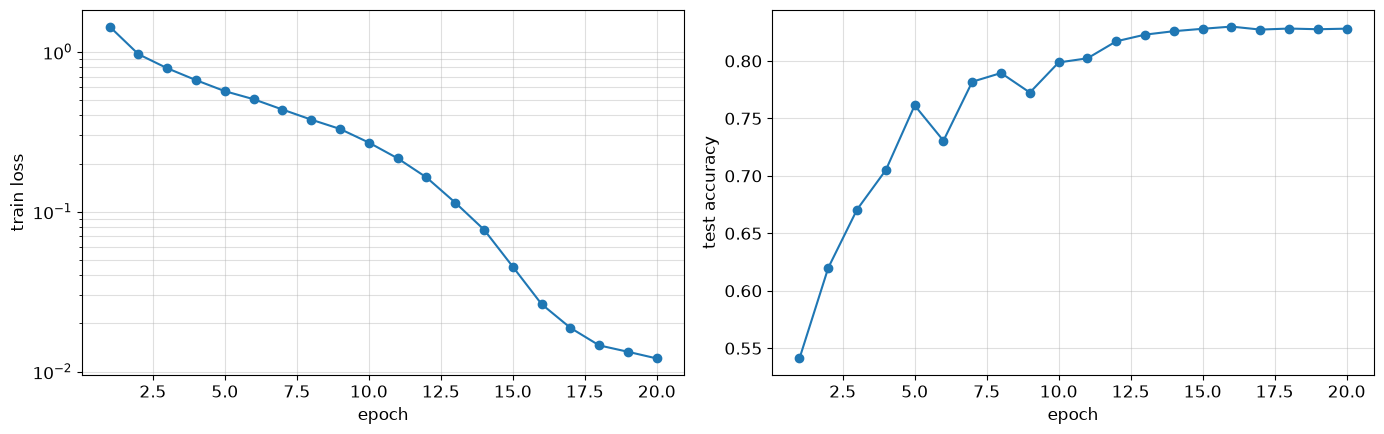

In [41]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
epochs_axis = range(1, len(history['test_acc']) + 1)
ax1.semilogy(epochs_axis, history['train_loss'], 'o-')
ax1.set_ylabel('train loss')
ax2.plot(epochs_axis, history['test_acc'], 'o-')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
plt.tight_layout()
plt.show()

**Вопрос.** Какой разрыв между train и test accuracy в конце обучения? Как ведут себя train loss и test accuracy на последних эпохах, когда learning rate уходит к нулю?

В конце обучения train accuracy = 0.9996 (на первых 10 000 объектах train), test accuracy = 0.828, разрыв ≈ 17.1 п.п.: сеть почти идеально запомнила train, но на test остаётся около 83%. Это ожидаемо: аугментаций нет, а в ResNet-20 около 272 тыс. параметров на 50 тыс. картинок, поэтому сеть способна подогнаться под train. На последних эпохах, когда lr по cosine уходит к нулю, train loss продолжает падать, но всё медленнее: 0.0264 → 0.0188 → 0.0146 → 0.0133 → 0.0121 (эпохи 16–20), а test accuracy стабилизируется около 0.828 (максимум 0.830 на 16-й эпохе, далее 0.827–0.828). Шаги становятся всё меньше, шум стохастического градиента перестаёт «гонять» веса вокруг минимума, поэтому кривые к концу сглаживаются, а дальнейшее снижение train loss уже не улучшает test accuracy. Ориентир 0.82 достигнут.

## 4.3 Абляции (1.5 балла)

Сравните **plain-20 и plain-56** при одинаковых `ABL_EPOCHS` и `LR`. Это два дополнительных обучения. Результат — `ablation[name] = dict(params, train_acc, test_acc, minutes, history)`, где `train_acc` считается на первых 10 000 объектах train, а `history` возвращается `train_cifar`.

Перед каждой конфигурацией вызовите `set_seed(0)`. Проверяем гипотезу: увеличение глубины plain-сети может затруднить оптимизацию даже на train ([He et al., 2015](https://arxiv.org/pdf/1512.03385)). Это не обещание, что при данном optimizer и коротком бюджете эффект обязательно появится. Отличайте результат «хуже на train» от «лучше на train, хуже на test». Для сравнения с residual-сетями нужен одинаковый протокол; основной ResNet-20 обучался дольше, его финальную accuracy нельзя напрямую трактовать как контроль этого опыта.

**Оценивание:** код — 0.2; эксперимент — 0.7; объяснение — 0.6 балла.

In [42]:
ABL_EPOCHS = 2 if FAST_MODE else 10
ABLATIONS = {
    'plain-20': dict(depth=20, residual=False),
    'plain-56': dict(depth=56, residual=False),
}

In [ ]:
ablation = {}
for name, cfg in ABLATIONS.items():
    set_seed(0)
    model = ResNetCIFAR(**cfg)
    started = time.perf_counter()
    hist = train_cifar(model, ABL_EPOCHS, LR, log=False)
    minutes = (time.perf_counter() - started) / 60
    train_acc = accuracy(predict_logits(model, X_train[:10_000], transform=normalize), Y_train[:10_000])
    ablation[name] = dict(params=n_params(model), train_acc=train_acc, test_acc=hist['test_acc'][-1], minutes=minutes, history=hist)

print(f'{"model":<22}{"params":>9}{"train acc":>11}{"test acc":>10}{"minutes":>9}')
for name, res in ablation.items():
    print(f'{name:<22}{res["params"]:>9,}{res["train_acc"]:>11.4f}{res["test_acc"]:>10.4f}{res["minutes"]:>9.1f}')

model                    params  train acc  test acc  minutes
plain-20                269,722     0.8600    0.7859      0.9
plain-56                853,018     0.5702    0.5391      2.5


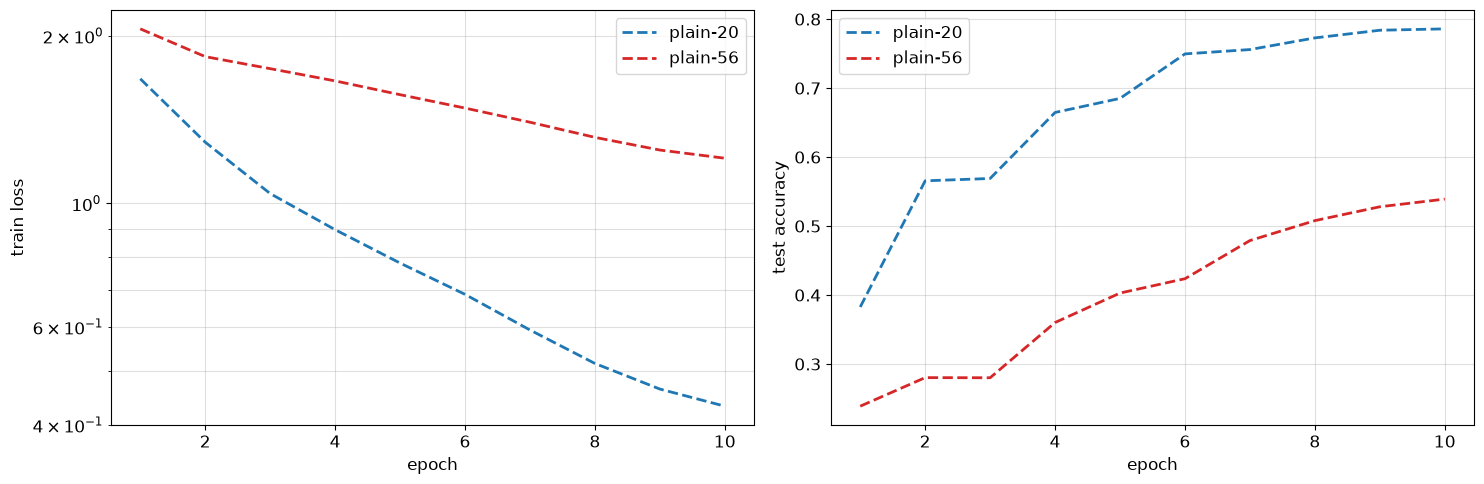

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
for name in ABLATIONS:
    hist = ablation[name]['history']
    style = '-' if name.startswith('ResNet') else '--'
    color = 'tab:blue' if '20' in name else 'tab:red'
    epochs_axis = range(1, len(hist['train_loss']) + 1)
    ax1.semilogy(epochs_axis, hist['train_loss'], style, color=color, linewidth=2, label=name)
    ax2.plot(epochs_axis, hist['test_acc'], style, color=color, linewidth=2, label=name)
ax1.set_ylabel('train loss')
ax2.set_ylabel('test accuracy')
for ax in (ax1, ax2):
    ax.set_xlabel('epoch')
    ax.grid(True, which='both', alpha=0.4)
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос.** Есть ли в вашем прогоне ухудшение train loss при увеличении глубины? Как изменились train и test accuracy? Какие наблюдения говорят о трудностях оптимизации, а какие — о переобучении? Если ухудшения на train нет, напишите это. Предложите **один** следующий контрольный эксперимент, позволяющий проверить ваше объяснение; запускать его не требуется.

plain-20: train acc 0.860, test acc 0.786, train loss в конце 0.432; plain-56: train acc 0.570, test acc 0.539, train loss в конце 1.205. Ухудшение train loss и train accuracy у более глубокой сети — признак трудностей оптимизации (она не может подогнаться даже под обучающие данные, как в He et al.); если же train accuracy у plain-56 такая же или выше, а test хуже, это переобучение или проблема обобщения, а не оптимизации. По моим числам наблюдается первый случай: у plain-56 train loss выше (1.205 против 0.432), train accuracy ниже (0.570 против 0.860, разница 29 п.п.), а разрыв train–test у plain-56 маленький (3 п.п.) в отличие от plain-20 (7.4 п.п.), то есть проблема именно в оптимизации, а не в переобучении. Остаётся неясным, зависит ли это от короткого бюджета (`ABL_EPOCHS = 10`), одного seed и выбранного lr: plain-56 к концу ещё не вышла на плато. Контрольный эксперимент (запускать не нужно): обучить ResNet-56 с `residual=True` при том же протоколе (`ABL_EPOCHS`, `LR`, seed). Если при тех же 56 слоях train loss станет таким же, как у plain-20, или лучше, причина в сложности оптимизации plain-сети без shortcut, а не в глубине или ёмкости как таковых.


---
# 5. Атаки

Модель — маленькая CNN на FashionMNIST (пиксели в $[0, 1]$, без `Normalize`). В финальном режиме модель учится на полном train, а серии атак идут по фиксированным 1000 test-объектам. Раздел 5.1 обязателен; далее выполняется только ветка, выбранная в `ATTACK_TRACK`. Все модели во время оценки атак находятся в `eval()`. Метрики на такой подвыборке имеют sampling noise; близкие результаты не следует ранжировать как надёжное преимущество.

In [45]:
N_FM_TRAIN = 12_000 if FAST_MODE else 60_000
N_FM_TEST = 256 if FAST_MODE else 1_000
FM_EPOCHS = 2 if FAST_MODE else 5

fm_train = datasets.FashionMNIST(DATA_ROOT, train=True, download=True)
fm_test = datasets.FashionMNIST(DATA_ROOT, train=False, download=True)
FM_CLASSES = fm_train.classes


def fm_tensors(ds, n):
    return (ds.data[:n, None].float() / 255).to(device), ds.targets[:n].to(device)


XF_train, YF_train = fm_tensors(fm_train, N_FM_TRAIN)
XF_test, YF_test = fm_tensors(fm_test, N_FM_TEST)
XF_train.shape, XF_test.shape

(torch.Size([60000, 1, 28, 28]), torch.Size([1000, 1, 28, 28]))

Модель, обучение и атаки FGSM и PGD в $L_\infty$ — готовый код:

In [46]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        )
        self.classifier = nn.Linear(64 * 7 * 7, n_classes)

    def forward(self, x):
        return self.classifier(self.features(x).flatten(1))


def train_fm(model, epochs=FM_EPOCHS, lr=1e-3):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        model.train()
        for x, y in iterate_batches(XF_train, YF_train, 128):
            loss = F.cross_entropy(model(x), y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
    model.eval()
    return model

In [47]:
def fgsm_attack(model, x, y, eps):
    x = x.detach()
    x_adv = x.clone().requires_grad_(True)
    with torch.enable_grad():
        grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
    return (x + eps * grad.sign()).clamp(0, 1).detach()


def pgd_attack(model, x, y, eps, alpha, steps, random_start=True):
    x = x.detach()
    x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) if random_start else x.clone()
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        x_adv = x_adv.detach() + alpha * grad.sign()
        x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
    return x_adv.detach()


def pgd(model, x, y, eps, steps=20):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / steps, steps=steps)


def attack_accuracy(model, X, Y, attack=None, batch_size=500, **attack_kwargs):
    model.eval()
    correct = 0
    for i in range(0, len(X), batch_size):
        x, y = X[i:i + batch_size], Y[i:i + batch_size]
        if attack is not None:
            x = attack(model, x, y, **attack_kwargs)
        with torch.no_grad():
            correct += (model(x).argmax(dim=1) == y).sum().item()
    return correct / len(X)


def assert_no_param_grads(model):
    assert all(p.grad is None for p in model.parameters())

In [48]:
set_seed(0)
started = time.perf_counter()
model_a = train_fm(SmallCNN())
RUN_TIMES['fashion_standard_seconds'] = time.perf_counter() - started
model_a.zero_grad(set_to_none=True)
{'clean': attack_accuracy(model_a, XF_test, YF_test),
 'FGSM, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, fgsm_attack, eps=0.1),
 'PGD-20, eps=0.1': attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)}

{'clean': 0.905, 'FGSM, eps=0.1': 0.064, 'PGD-20, eps=0.1': 0.0}

## 5.1 PGD в $L_2$ (1 балл)

Ограничение $\|\delta\|_2 \le \varepsilon$. Линеаризация loss (как при выводе FGSM) даёт шаг по нормированному градиенту, а проекция на шар — масштабирование:
$$
x' = x^{(k)} + \alpha\, \frac{g}{\|g\|_2}, \qquad
\delta = x' - x, \qquad
x^{(k+1)} = \mathrm{clip}_{[0, 1]}\Big(x + \delta \cdot \min\big(1,\, \tfrac{\varepsilon}{\|\delta\|_2}\big)\Big).
$$
Нормы — по каждой картинке отдельно. Старт из $x$ (без random start).

**Оценивание:** код — 0.6; эксперимент — 0.2; объяснение — 0.2 балла.

In [ ]:
def pgd_l2(model, x, y, eps, alpha, steps):
    x = x.detach()
    x_adv = x.clone() # старт из x
    for _ in range(steps):
        x_adv.requires_grad_(True)
        with torch.enable_grad():
            grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y), x_adv)
        g_norm = grad.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1) # длина градиента каждой картинки
        x_new = x_adv.detach() + alpha * grad / g_norm # шаг длины alpha по направлению градиента
        delta = x_new - x # насколько всего ушли от оригинала
        d_norm = delta.flatten(1).norm(dim=1).clamp_min(1e-12).view(-1, 1, 1, 1)
        delta = delta * torch.clamp(eps / d_norm, max=1.0) # если ушли дальше eps возвращаем на границу шара
        x_adv = (x + delta).clamp(0, 1) # пиксели должны оставаться в [0, 1]
    return x_adv.detach()

In [50]:
x, y = XF_test[:500], YF_test[:500]
eps2 = 2.0
x_adv = pgd_l2(model_a, x, y, eps=eps2, alpha=2.5 * eps2 / 20, steps=20)
assert (x_adv - x).flatten(1).norm(dim=1).max() <= eps2 + 1e-4
assert x_adv.min() >= 0 and x_adv.max() <= 1 and not x_adv.requires_grad
assert_no_param_grads(model_a)
acc_clean, acc_l2 = attack_accuracy(model_a, x, y), attack_accuracy(model_a, x_adv, y)
print(f'Падение accuracy под PGD-L2: {acc_clean - acc_l2:.3f}; маленькое падение требует диагностики.')
acc_clean, acc_l2

Падение accuracy под PGD-L2: 0.914; маленькое падение требует диагностики.


(0.914, 0.0)

In [51]:
def pgd_l2_20(model, x, y, eps):
    return pgd_l2(model, x, y, eps, alpha=2.5 * eps / 20, steps=20)


eps_l2 = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0]
acc_l2 = [attack_accuracy(model_a, XF_test, YF_test, pgd_l2_20, eps=e) for e in eps_l2]
acc_linf = attack_accuracy(model_a, XF_test, YF_test, pgd, eps=0.1)
dict(zip(eps_l2, acc_l2)), acc_linf

({0.0: 0.905,
  0.5: 0.469,
  1.0: 0.084,
  1.5: 0.006,
  2.0: 0.0,
  3.0: 0.0,
  4.0: 0.0},
 0.003)

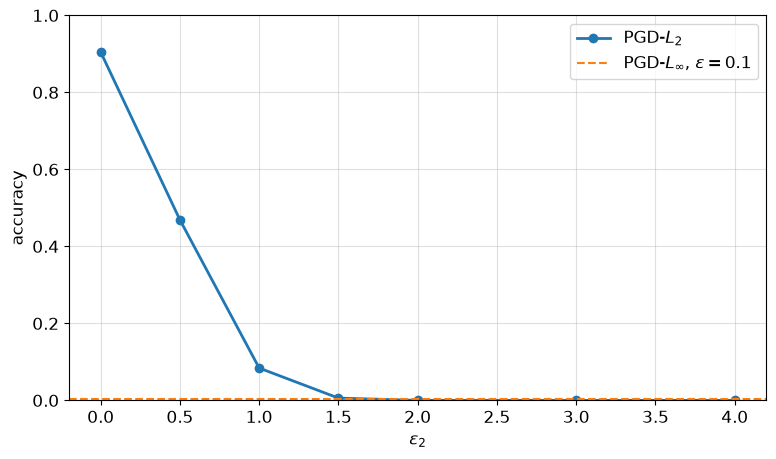

In [52]:
plt.figure(figsize=(9, 5))
plt.plot(eps_l2, acc_l2, 'o-', linewidth=2, label=r'PGD-$L_2$')
plt.axhline(acc_linf, color='tab:orange', linestyle='--', label=r'PGD-$L_\infty$, $\varepsilon = 0.1$')
plt.xlabel(r'$\varepsilon_2$')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

Возмущения обеих атак на одних картинках; $\varepsilon_2$ — ближайшая по accuracy точка проверенной сетки. Если разница велика, сравнение не следует называть сравнением при равной силе атаки. Цветовая шкала каждой карты нормирована отдельно; абсолютные нормы выведены под рисунком:

Ближайшая точка сетки: eps2=1.5, accuracy gap=0.003


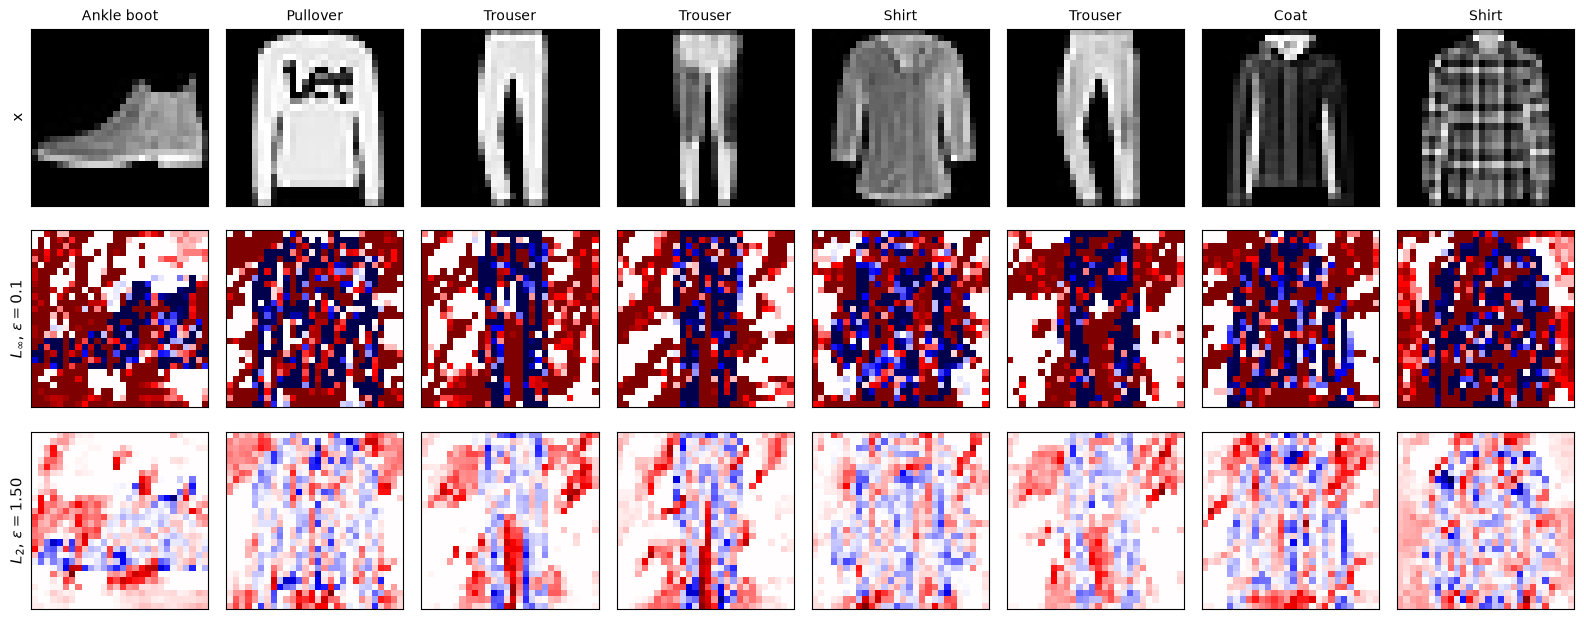

$L_\infty$, $\varepsilon=0.1$ L_inf = 0.100   L_2 = 2.148
$L_2$, $\varepsilon=1.50$    L_inf = 0.269   L_2 = 1.492


In [53]:
# Поиск ближайшей проверенной точки не предполагает монотонность конечной PGD.
match_idx = int(np.argmin(np.abs(np.asarray(acc_l2) - acc_linf)))
eps2_match = float(eps_l2[match_idx])
print(f'Ближайшая точка сетки: eps2={eps2_match}, accuracy gap={abs(acc_l2[match_idx] - acc_linf):.3f}')
x8, y8 = XF_test[:8], YF_test[:8]
torch.manual_seed(0)
deltas = {r'$L_\infty$, $\varepsilon=0.1$': pgd(model_a, x8, y8, 0.1) - x8,
          rf'$L_2$, $\varepsilon={eps2_match:.2f}$': pgd_l2_20(model_a, x8, y8, eps2_match) - x8}
fig, axes = plt.subplots(3, 8, figsize=(16, 6.5))
for i in range(8):
    axes[0, i].imshow(x8[i, 0].cpu(), cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(FM_CLASSES[y8[i]], fontsize=10)
    for row, d in enumerate(deltas.values(), start=1):
        vmax = d[i].abs().max().item()
        axes[row, i].imshow(d[i, 0].cpu(), cmap='seismic', vmin=-vmax, vmax=vmax)
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
for ax, label in zip(axes[:, 0], ['x'] + list(deltas)):
    ax.set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()
for name, d in deltas.items():
    print(f'{name:<28} L_inf = {d.abs().amax(dim=(1, 2, 3)).mean():.3f}   L_2 = {d.flatten(1).norm(dim=1).mean():.3f}')

**Вопрос.** Какая точка сетки $\varepsilon_2$ ближе всего по accuracy к $L_\infty$-атаке с $\varepsilon = 0.1$ и как велик остаточный разрыв? Какова $L_2$-норма самого $L_\infty$-возмущения? Где сосредоточено $L_2$-возмущение на ваших изображениях и как это связано с нормированным градиентом?

Ближе всего по accuracy к $L_\infty$-атаке ($\varepsilon = 0.1$, accuracy 0.003) точка $\varepsilon_2 = 1.5$ (accuracy 0.006), остаточный разрыв 0.003 (точка 2.0 с accuracy 0.000 отстоит на столько же); но при $\varepsilon_2 \ge 2$ accuracy уже нулевая, так что это сравнение двух атак, обе из которых почти полностью ломают модель, а не сравнение при равной силе (для $\varepsilon_2 = 0.5;\ 1.0;\ 1.5$ accuracy 0.469; 0.084; 0.006). $L_2$-норма самого $L_\infty$-возмущения в среднем 2.148 (максимум возможного $0.1\sqrt{784} \approx 2.8$), то есть заметно больше радиуса $L_2$-атаки 1.5 (её реальная норма 1.492): $L_2$-атака достигает почти той же accuracy при примерно на 30% меньшей $L_2$-норме. $L_2$-возмущение сосредоточено в нескольких компактных областях: у подошвы ботинка, между штанинами брюк, по контурам одежды и в соседних областях фона, где градиент большой, с пиками $|\delta|$ (в среднем $L_\infty$-норма 0.269 против 0.1), а остальные пиксели почти не меняются. Так происходит потому, что шаг $\alpha\, g / \|g\|_2$ пропорционален самому градиенту, и пиксели с большим $|g_i|$ получают большое изменение, а с малым — почти нулевое; $\mathrm{sign}(g)$ у $L_\infty$-атаки, напротив, даёт всем пикселям одинаковую амплитуду $\pm 0.1$ (на картинках это почти сплошные насыщенные красные и синие пиксели). Вывод — по одной модели и 1000 картинкам.

## 5.2 Targeted attack (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'targeted'`. Ветку 5.3 при этом можно оставить пустой.

Цель — не просто ошибка, а заданный класс $t$: минимизируем loss по целевой метке
$$
x^{(k+1)} = \Pi_{B_\infty(x, \varepsilon)}\Big[x^{(k)} - \alpha\, \mathrm{sign}\, \nabla_x L\big(f(x^{(k)}), t\big)\Big].
$$

1. Реализуйте `pgd_targeted` ($L_\infty$, random start, как `pgd_attack`).
2. Реализуйте `targeted_success_matrix`: $S[s, t]$ — доля всех картинок класса $s$, которые после атаки с целью $t$ классифицируются как $t$, включая изначально ошибочные. Верните CPU-тензор; диагональ и строки отсутствующих классов — `nan`. Обрабатывайте вход батчами не более 128 объектов, сигнатуру менять не нужно. Сопоставьте результат с готовой clean confusion matrix ниже.

**Оценивание:** код — 1; эксперимент — 0.4; объяснение — 0.6 балла.

In [ ]:
if ATTACK_TRACK == 'targeted':
    def pgd_targeted(model, x, target, eps, alpha, steps):
        x = x.detach()
        x_adv = (x + torch.empty_like(x).uniform_(-eps, eps)).clamp(0, 1) # случайный старт
        for _ in range(steps):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), target), x_adv)
            x_adv = x_adv.detach() - alpha * grad.sign()
            x_adv = torch.clamp(x_adv, min=x - eps, max=x + eps).clamp(0, 1)
        return x_adv.detach()


    def targeted_success_matrix(model, x, y, eps, steps=20, n_classes=10):
        model.eval()
        alpha = 2.5 * eps / steps
        S = torch.full((n_classes, n_classes), float('nan'))
        for s in range(n_classes):
            xs = x[y == s] # все картинки класса s
            if len(xs) == 0:
                continue
            for t in range(n_classes):
                if t == s:
                    continue
                hits = 0
                for i in range(0, len(xs), 128): # батчи не больше 128
                    xb = xs[i:i + 128]
                    target = torch.full((len(xb),), t, dtype=torch.long, device=xb.device)
                    x_adv = pgd_targeted(model, xb, target, eps, alpha, steps)
                    with torch.no_grad():
                        hits += (model(x_adv).argmax(dim=1) == t).sum().item()
                S[s, t] = hits / len(xs) # доля всех картинок класса s
        return S

In [55]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    x, y = XF_test[:1000], YF_test[:1000]
    target = (y + 1) % 10
    x_t = pgd_targeted(model_a, x, target, eps=0.1, alpha=0.0125, steps=20)
    assert (x_t - x).abs().max() <= 0.1 + 1e-6 and x_t.min() >= 0 and x_t.max() <= 1
    assert_no_param_grads(model_a)
    with torch.no_grad():
        hit_rate = (model_a(x_t).argmax(dim=1) == target).float().mean().item()
    print(f'Targeted hit rate: {hit_rate:.3f}; сравните с частотой целевого класса до атаки.')
    hit_rate

Targeted hit rate: 0.726; сравните с частотой целевого класса до атаки.


Clean confusion matrix (строки: true, столбцы: predicted):
[[0.96 0.   0.   0.   0.   0.   0.04 0.   0.   0.  ]
 [0.   0.99 0.   0.01 0.   0.   0.   0.   0.   0.  ]
 [0.04 0.   0.86 0.01 0.05 0.   0.05 0.   0.   0.  ]
 [0.11 0.   0.01 0.84 0.01 0.   0.03 0.   0.   0.  ]
 [0.   0.   0.12 0.03 0.78 0.   0.06 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.95 0.   0.03 0.   0.01]
 [0.1  0.   0.08 0.03 0.03 0.   0.75 0.   0.   0.  ]
 [0.   0.   0.   0.   0.   0.   0.   0.99 0.01 0.  ]
 [0.01 0.   0.   0.   0.   0.   0.   0.   0.99 0.  ]
 [0.   0.   0.   0.   0.   0.01 0.   0.04 0.   0.95]]


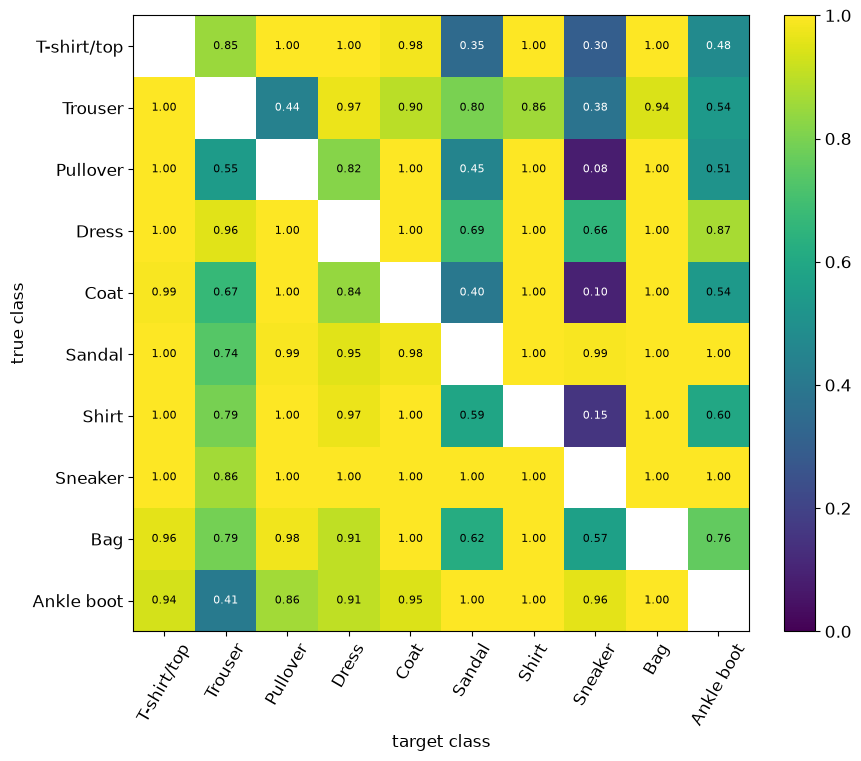

In [56]:
if ATTACK_TRACK == 'targeted':
    torch.manual_seed(0)
    S = targeted_success_matrix(model_a, XF_test, YF_test, eps=0.1)
    assert S.shape == (10, 10) and torch.isnan(S.diagonal()).all()
    pred_clean = predict_logits(model_a, XF_test).argmax(1)
    clean_confusion = torch.bincount((10 * YF_test + pred_clean).cpu(), minlength=100).reshape(10, 10).float()
    clean_confusion /= clean_confusion.sum(1, keepdim=True).clamp_min(1)
    print('Clean confusion matrix (строки: true, столбцы: predicted):')
    print(np.round(clean_confusion.numpy(), 2))

    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(S, cmap='viridis', vmin=0, vmax=1)
    for s, t in itertools.product(range(10), range(10)):
        if s != t:
            ax.text(t, s, f'{S[s, t]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if S[s, t] < 0.5 else 'black')
    ax.set_xticks(range(10), FM_CLASSES, rotation=60)
    ax.set_yticks(range(10), FM_CLASSES)
    ax.set_xlabel('target class')
    ax.set_ylabel('true class')
    plt.colorbar(im, fraction=0.046)
    plt.show()

**Вопрос.** Какие пары (истинный класс, целевой класс) атакуются легче всего, какие труднее? Симметрична ли матрица? Как это связано с тем, какие классы модель путает без атаки?

Hit rate для цели $(y+1) \bmod 10$ равен 0.726 при $\varepsilon = 0.1$, тогда как до атаки модель называла этот класс лишь в доле порядка 0.3% случаев (по clean confusion matrix); среднее по всем 90 парам — 0.83, и 39 пар из 90 дают $S \ge 0.99$. Легче всего (доля $\approx 1.0$) пары T-shirt → Pullover / Dress / Shirt / Bag и Sneaker → любой другой класс (в среднем 0.98 по строке); самые «лёгкие» цели — T-shirt и Bag (в среднем 0.99 по столбцу), Shirt и Coat (0.98). Труднее всего сделать Sneaker из одежды: Pullover → Sneaker 0.08, Coat → Sneaker 0.10, Shirt → Sneaker 0.15, T-shirt → Sneaker 0.30 (столбец Sneaker в среднем 0.46); также трудны цели Sandal (0.65) и Ankle boot (0.70) и пара Trouser → Pullover 0.44. Матрица несимметрична: средний $|S[s,t] - S[t,s]|$ равен 0.24, максимум 0.92 (Sneaker → Pullover 1.00, а Pullover → Sneaker 0.08), то есть «лёгкость» определяется скорее целевым классом, чем расстоянием между классами. Связь с clean confusion есть, но слабая (корреляция по 90 парам около 0.27): без атаки модель путает T-shirt / Shirt / Dress / Pullover / Coat, и это же лёгкие пары для атаки; но много лёгких пар (например, T-shirt → Bag, Sneaker → Coat) в clean confusion вообще нулевые. Вывод — по одной модели; на строку приходится около 100 картинок, поэтому доли имеют шаг порядка 0.01 и заметный шум.

## 5.3 Transfer (2 балла, вариант на выбор)

Выполняется при `ATTACK_TRACK = 'transfer'`. Ветку 5.2 при этом можно оставить пустой.

Black-box сценарий: атакующий не видит модель-жертву, строит атаку на своей модели и надеется, что она перенесётся. Обучите `model_b` (та же архитектура, `set_seed(1)`) и MLP с двумя скрытыми слоями по 512 нейронов и ReLU (`set_seed(2)`). Атаки FGSM и PGD-20 с $\varepsilon = 0.1$, построенные на `model_a`, проверьте на всех трёх моделях. Результат — `transfer[attack][victim] = accuracy`, атаки `'clean'`, `'FGSM'`, `'PGD-20'`, жертвы `'model A (source)'`, `'model B'`, `'MLP'`.

**Оценивание:** код — 0.6; эксперимент — 0.8; объяснение — 0.6 балла.

In [57]:
if ATTACK_TRACK == 'transfer':
    # ваш код
    raise NotImplementedError
    print(f'{"":<8}' + ''.join(f'{name:>18}' for name in transfer['clean']))
    for attack, row in transfer.items():
        print(f'{attack:<8}' + ''.join(f'{acc:>18.3f}' for acc in row.values()))

**Вопрос.** Для каждой жертвы укажите падение accuracy относительно её собственного clean baseline. Сравните с падением на source-модели. Какая атака и на какую архитектуру переносится лучше в вашем прогоне? Предложите объяснение и укажите, почему одного seed недостаточно для общего вывода о превосходстве архитектуры или атаки.

**Ответ.**

---
# 6. Adversarial training

## 6.1 PGD adversarial training (2 балла)

[Towards Deep Learning Models Resistant to Adversarial Attacks](https://arxiv.org/pdf/1706.06083), Madry et al., 2017:
$$
\min_\theta\; \mathbb E_{(x, y)} \Big[\max_{\|\delta\|_\infty \le \varepsilon} L\big(f_\theta(x + \delta), y\big)\Big].
$$
На каждом батче внутренний max приближается атакой, и шаг оптимизатора делается только по adversarial-примерам, без clean-части. Модель — с нуля.

Реализуйте `adversarial_train(model, eps, attack, epochs)`: `attack(model, x, y, eps)` возвращает detached `x_adv`. Используйте `torch.optim.Adam` с переданным `lr`, batch size 128, cross-entropy только на adversarial-примерах. Генерация атаки — в `eval()`, обновление весов — в `train()`; не дифференцируйте через построение атаки. После каждой эпохи записывайте clean, FGSM и PGD-20 accuracy на `XF_test[:1000]` с тем же $\varepsilon$. Перед возвратом включите `eval()` и очистите `.grad` параметров.

В обязательной части обучается одна модель с PGD-7. FGSM и FGSM-RS из готового словаря нужны только для бонуса 7.5.

**Оценивание:** код — 1; эксперимент — 0.6; объяснение — 0.4 балла.

In [58]:
def fgsm_rs_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=1.25 * eps, steps=1, random_start=True)


def pgd7_attack(model, x, y, eps):
    return pgd_attack(model, x, y, eps, alpha=2.5 * eps / 7, steps=7)


TRAIN_ATTACKS = {'FGSM': fgsm_attack, 'FGSM-RS': fgsm_rs_attack, 'PGD-7': pgd7_attack}
AT_EPOCHS = 2 if FAST_MODE else 5

In [59]:
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
def adversarial_train(model, eps, attack, epochs=AT_EPOCHS, lr=1e-3, log=True):
    model = model.to(device)
    history = dict(clean=[], fgsm=[], pgd=[])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    X_eval, Y_eval = XF_test[:1000], YF_test[:1000] # фиксированная подвыборка для оценки

    for epoch in range(epochs):
        for x, y in iterate_batches(XF_train, YF_train, 128):
            model.eval() # атаку строим в eval-режиме
            x_adv = attack(model, x, y, eps)
            model.train()
            loss = F.cross_entropy(model(x_adv), y) # учимся только на атакованных
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        clean = attack_accuracy(model, X_eval, Y_eval)
        fgsm = attack_accuracy(model, X_eval, Y_eval, fgsm_attack, eps=eps)
        pgd_acc = attack_accuracy(model, X_eval, Y_eval, pgd, eps=eps)
        history['clean'].append(clean)
        history['fgsm'].append(fgsm)
        history['pgd'].append(pgd_acc)
        if log:
            print(f'epoch {epoch + 1}: clean {clean:.3f} | FGSM {fgsm:.3f} | PGD {pgd_acc:.3f}')

    model.eval()
    model.zero_grad(set_to_none=True) # не оставляем градиенты в параметрах
    return history
    return history

In [60]:
EPS_TRAIN = 0.1
robust, at_history = {}, {}
for name in ['PGD-7']:
    print(name)
    set_seed(0)
    robust[name] = SmallCNN()
    started = time.perf_counter()
    at_history[name] = adversarial_train(robust[name], EPS_TRAIN, TRAIN_ATTACKS[name])
    RUN_TIMES['fashion_pgd_at_seconds'] = time.perf_counter() - started
if not FAST_MODE and at_history['PGD-7']['pgd'][-1] <= 0.5:
    print('PGD accuracy ниже ориентира 0.5: проверьте обучение и обсудите результат; это не автопровал задания.')

PGD-7
epoch 1: clean 0.779 | FGSM 0.668 | PGD 0.626
epoch 2: clean 0.824 | FGSM 0.720 | PGD 0.694
epoch 3: clean 0.833 | FGSM 0.738 | PGD 0.697
epoch 4: clean 0.828 | FGSM 0.732 | PGD 0.712
epoch 5: clean 0.844 | FGSM 0.747 | PGD 0.718


In [61]:
eps_grid = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
models_eval = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
torch.manual_seed(0)
robust_curves = {name: [attack_accuracy(m, XF_test, YF_test, pgd, eps=e) if e > 0 else attack_accuracy(m, XF_test, YF_test)
                        for e in eps_grid] for name, m in models_eval.items()}
for name, accs in robust_curves.items():
    print(f'{name:<10}' + ''.join(f'{a:>8.3f}' for a in accs))

standard     0.905   0.128   0.001   0.000   0.000   0.000
PGD-AT       0.844   0.780   0.721   0.475   0.126   0.000


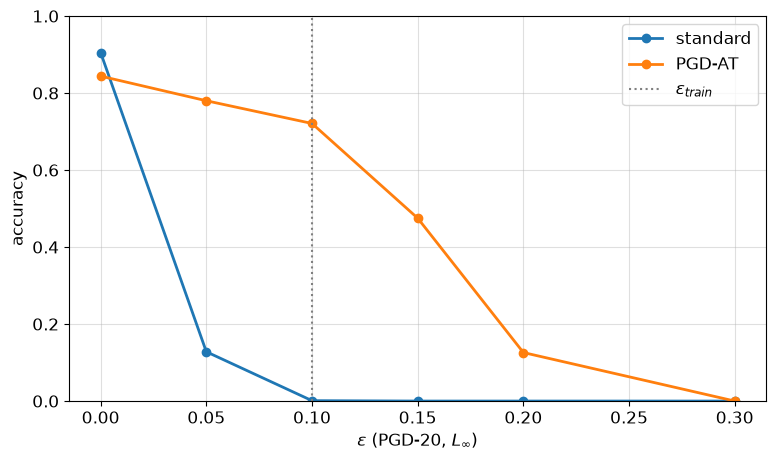

In [62]:
plt.figure(figsize=(9, 5))
for name, accs in robust_curves.items():
    plt.plot(eps_grid, accs, 'o-', linewidth=2, label=name)
plt.axvline(EPS_TRAIN, color='gray', linestyle=':', label=r'$\varepsilon_{train}$')
plt.xlabel(r'$\varepsilon$ (PGD-20, $L_\infty$)')
plt.ylabel('accuracy')
plt.ylim(0, 1)
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Сколько стоит робастность в clean accuracy? Что происходит при $\varepsilon > \varepsilon_{\text{train}}$? Во сколько раз PGD-AT дороже обычного обучения по числу forward/backward?

Робастность стоит 6.1 п.п. clean accuracy: 0.844 у PGD-AT против 0.905 у стандартной модели, но при этом PGD-20 accuracy при $\varepsilon = 0.1$ вырастает с 0.001 до 0.721 (при $\varepsilon = 0.05$ — с 0.128 до 0.780). При $\varepsilon > \varepsilon_{\text{train}}$ робастность быстро теряется: 0.475 при $\varepsilon = 0.15$, 0.126 при 0.2 и 0.000 при 0.3 (стандартная модель получает 0.001 уже при $\varepsilon = 0.1$), т.е. защита не переносится на радиусы заметно больше обучающего. PGD-7 AT делает на батч 7 шагов атаки (прямой и обратный проход по входу) и один шаг обучения, итого 8 forward/backward против 1 у обычного обучения; в моём прогоне время 37.9 с против 4.8 с, то есть 8.0 раза. 

## 6.2 Диагностика оценки robustness (1 балл)

Реализуйте `sanity_checks(model, x, y, eps)` и верните четыре accuracy:

- `fgsm` — после FGSM;
- `pgd20` — после PGD-20 с random start;
- `pgd100_x5` — PGD-100 с пятью random restarts: объект считается сломанным, если он ошибочно классифицирован хотя бы в одном restart **или уже на clean**;
- `eps_1` — после PGD-20 с $\varepsilon=1$.

Для каждого поля clean-ошибки тоже считаются ошибками: атака не должна «исправлять» robust accuracy. Атакуйте батчами не более 128. В `FAST_MODE` сокращается только число объектов, число шагов и restarts остаётся тем же.

Обычно усиление атаки уменьшает accuracy; обратный результат — повод проверить step size, random start и loss. Независимые конечные PGD-прогоны не дают гарантированного порядка результатов. Низкая accuracy при большом радиусе — полезная диагностика, но прохождение всех sanity checks не доказывает отсутствие gradient masking и не сертифицирует robustness. См. [Athalye et al., 2018](https://arxiv.org/abs/1802.00420).

Эксперимент проводится на фиксированных первых 128 объектах в FAST_MODE и 256 в финальном режиме. Это диагностика, а не точная оценка accuracy всего датасета.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def sanity_checks(model, x, y, eps):
    model.eval()

    def survived(attack, **kw):
        # доля картинок, которые верны на clean И верны после атаки
        ok = 0
        for i in range(0, len(x), 128): # батчи не больше 128
            xb, yb = x[i:i + 128], y[i:i + 128]
            with torch.no_grad():
                good = model(xb).argmax(1) == yb # верны ли на clean
            x_adv = attack(model, xb, yb, **kw)
            with torch.no_grad():
                good &= model(x_adv).argmax(1) == yb # верны после атаки
            ok += good.sum().item()
        return ok / len(x)

    def pgd100_x5_survived():
        ok = 0
        for i in range(0, len(x), 128):
            xb, yb = x[i:i + 128], y[i:i + 128]
            with torch.no_grad():
                good = model(xb).argmax(1) == yb
            for _ in range(5): # 5 перезапусков
                x_adv = pgd(model, xb, yb, eps=eps, steps=100)
                with torch.no_grad():
                    good &= model(x_adv).argmax(1) == yb # сломан хотя бы раз остаётся False
            ok += good.sum().item()
        return ok / len(x)

    return {
        'fgsm': survived(fgsm_attack, eps=eps),
        'pgd20': survived(pgd, eps=eps, steps=20),
        'pgd100_x5': pgd100_x5_survived(),
        'eps_1': survived(pgd, eps=1.0, steps=20),
    }

In [64]:
torch.manual_seed(0)
N_SANITY = 128 if FAST_MODE else 256
checks = {name: sanity_checks(m, XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_TRAIN)
          for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
print(f'{"model":<22}' + ''.join(f'{k:>11}' for k in next(iter(checks.values()))))
for name, res in checks.items():
    assert set(res) == {'fgsm', 'pgd20', 'pgd100_x5', 'eps_1'}
    assert all(math.isfinite(v) and 0 <= v <= 1 for v in res.values())
    print(f'{name:<22}' + ''.join(f'{v:>11.3f}' for v in res.values()))

model                        fgsm      pgd20  pgd100_x5      eps_1
standard                    0.074      0.004      0.000      0.000
PGD-AT                      0.754      0.727      0.719      0.000


**Вопрос.** Насколько меняется оценка accuracy при усилении атаки? Есть ли подозрительные результаты и что вы проверили бы дополнительно? Может ли модель с высокой FGSM accuracy и почти нулевой PGD accuracy пройти все перечисленные sanity checks — и что тогда можно сказать о её robustness?

У стандартной модели accuracy падает с FGSM 0.074 до PGD-20 0.004 и до 0.000 у PGD-100×5; у PGD-AT: FGSM 0.754, PGD-20 0.727, PGD-100×5 0.719, т.е. усиление атаки снижает accuracy монотонно (на 2.7 п.п. при переходе от FGSM к PGD-20 и только на 0.8 п.п. при переходе к PGD-100 с 5 рестартами), а при $\varepsilon = 1$ accuracy равна 0.000 у обеих моделей, как и должно быть при радиусе, позволяющем сделать любую картинку. Подозрительных результатов, то есть обратного порядка, нет; разница PGD-20 и PGD-100×5 меньше 1 п.п. при $N = 256$ (стандартная ошибка около 2.8 п.п., один объект — 0.4 п.п.) статистически неразличима, и это означает лишь, что PGD-20 почти исчерпывает атаку из данного семейства. Дополнительно я проверил бы transfer-атаку с независимой модели (она должна быть слабее white-box), атаку без градиентов (например, Square Attack) или ансамбль вроде AutoAttack и поведение loss вдоль направления атаки. Модель с высокой FGSM accuracy и почти нулевой PGD accuracy формально может пройти все четыре проверки, потому что порядок «FGSM ≥ PGD-20 ≥ PGD-100 ≥ eps_1» у неё сохраняется и $\varepsilon = 1$ даёт ноль; сами эти проверки ловят только обратный порядок и ненулевой eps_1. Но её настоящая робастность — это минимальная из оценок, то есть почти нулевая, а высокая FGSM accuracy — симптом маскирования градиента или catastrophic overfitting; прохождение проверок робастность не доказывает (Athalye et al., 2018).

## 6.3 Градиент по входу у обычной и робастной модели (1 балл)

Карта $|\nabla_x z_y(x)|$ — saliency по логиту верного класса: $z_c(x)$ обозначает логит класса $c$, $y$ — верную метку. Это **другая величина**, чем градиент cross-entropy в FGSM. Если $p_c(x)=\mathrm{softmax}(z(x))_c$, то
$$
\nabla_x L_{\mathrm{CE}}(x,y)=\sum_c p_c(x)\nabla_x z_c(x)-\nabla_x z_y(x).
$$
Для некоторых adversarially trained моделей наблюдали более интерпретируемые input gradients ([Tsipras et al., 2019](https://arxiv.org/pdf/1805.12152)). Здесь проверяется, наблюдается ли такой эффект в нашем протоколе; вид saliency сам по себе не доказывает robustness.

1. Реализуйте `input_gradient(model, x, y)`, возвращающую $|\nabla_x z_y|$ для батча (без изменения `.grad` параметров).
2. Для стандартной модели и PGD-AT посчитайте долю массы градиента на фоне (пиксели с $x = 0$), среднюю по `XF_test[:1000]`, и нарисуйте карты для 8 картинок.

**Оценивание:** код — 0.5; эксперимент — 0.2; объяснение — 0.3 балла.

In [ ]:
def input_gradient(model, x, y):
    model.eval()
    x = x.detach().clone().requires_grad_(True)
    with torch.enable_grad():
        z_y = model(x).gather(1, y[:, None]).sum()
        grad, = torch.autograd.grad(z_y, x)
    return grad.abs().detach()


def background_share(s, x):
    return ((s * (x == 0)).flatten(1).sum(1) / s.flatten(1).sum(1).clamp_min(1e-12)).mean().item()

In [66]:
x, y = XF_test[:1000], YF_test[:1000]
g = input_gradient(model_a, x, y)
assert g.shape == x.shape and (g >= 0).all()
assert_no_param_grads(model_a)
x1 = x[:1].clone().requires_grad_(True)
manual, = torch.autograd.grad(model_a(x1)[0, y[0]], x1)
assert torch.allclose(g[:1], manual.abs())

grad_models = {'standard': model_a, 'PGD-AT': robust['PGD-7']}
shares = {name: background_share(input_gradient(m, x, y), x) for name, m in grad_models.items()}
print(f'background pixels: {(x == 0).float().mean():.3f}')
shares

background pixels: 0.498


{'standard': 0.5653191804885864, 'PGD-AT': 0.22201357781887054}

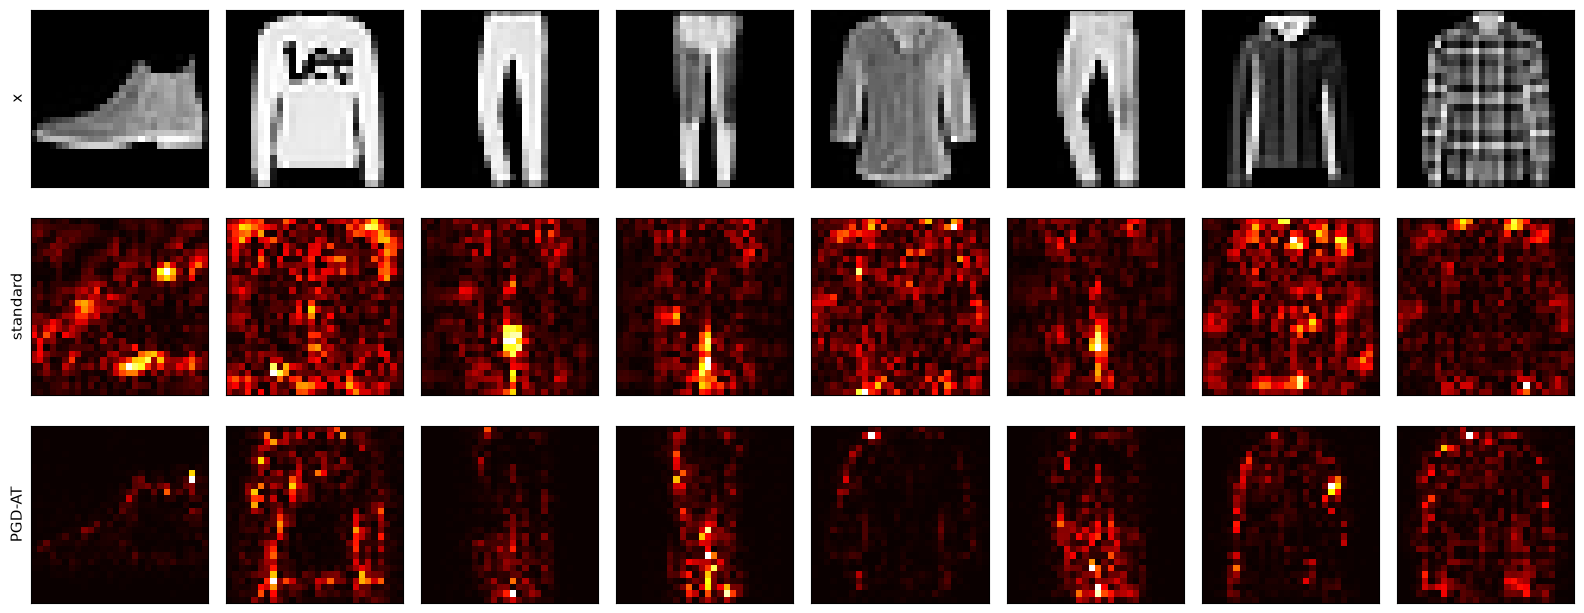

In [67]:
x8, y8 = XF_test[:8], YF_test[:8]
rows = {'x': x8} | {name: input_gradient(m, x8, y8) for name, m in grad_models.items()}
fig, axes = plt.subplots(len(rows), 8, figsize=(16, 2.2 * len(rows)))
for row, (label, images) in enumerate(rows.items()):
    for i in range(8):
        axes[row, i].imshow(images[i, 0].cpu(), cmap='gray' if row == 0 else 'hot')
        axes[row, i].set_xticks([])
        axes[row, i].set_yticks([])
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.tight_layout()
plt.show()

**Вопрос.** Чем отличаются карты моделей — визуально и по доле массы на фоне? Согласуется ли наблюдение с различием PGD accuracy в вашем эксперименте? Почему одной красивой saliency-карты недостаточно для вывода о robustness?

Карты стандартной модели «шумные»: яркие пиксели разбросаны по всему изображению, в том числе по фону, а у PGD-AT градиент темнее и собран у контуров и границ одежды (например, контур свитера, рубашки, промежуток между штанинами), фон в основном тёмный. Количественно: пикселей фона (с $x = 0$) 49.8%, но на фон приходится 56.5% массы градиента у стандартной модели против 22.2% у PGD-AT, то есть у стандартной модели доля фона выше доли самих фоновых пикселей, у PGD-AT — более чем вдвое ниже. Это согласуется с различием PGD-20 accuracy (0.001 против 0.721 при $\varepsilon = 0.1$): робастная модель опирается на форму объекта, а не на фон. Но это согласие, а не доказательство: saliency — градиент в одной точке (локальная линейная картина), она может выглядеть аккуратно и у модели с замаскированным градиентом; результат зависит от нормировки цветовой шкалы и выбора 8 картинок; а робастность определяется поведением в целом шаре радиуса $\varepsilon$, которое проверяют только атаками с разными стратегиями, поэтому одной красивой карты недостаточно.

### Сохранение результатов обязательной части

Ячейка сохраняет `metrics.json` и три checkpoint в `artifacts/`. Выполняется и в FAST_MODE для проверки формата; при окончательном прогоне файлы перезаписываются с `fast_mode=false`. Сдайте их вместе с ноутбуком. NaN в матрице targeted success записываются как JSON `null`. Checkpoints содержат только `state_dict`, без сериализации объекта модели.

In [68]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    return value


artifact_dir = Path('artifacts')
artifact_dir.mkdir(exist_ok=True)
metrics = dict(
    schema_version=2, fast_mode=FAST_MODE, attack_track=ATTACK_TRACK,
    environment=dict(torch=torch.__version__, device=str(device)),
    data=dict(cifar_train=len(X_train), cifar_test=len(X_test),
              fashion_train=len(XF_train), fashion_test=len(XF_test)),
    config=dict(seed=0, cifar_epochs=EPOCHS, ablation_epochs=ABL_EPOCHS,
                cifar_lr=LR, cifar_mean=CIFAR_MEAN, cifar_std=CIFAR_STD,
                fashion_epochs=FM_EPOCHS, at_epochs=AT_EPOCHS, eps_train=EPS_TRAIN),
    cifar=dict(history=history_cifar, ablations=ablation),
    attacks=dict(l2_eps=eps_l2, l2_accuracy=acc_l2, linf_accuracy=acc_linf,
                 selected=S if ATTACK_TRACK == 'targeted' else transfer),
    adversarial=dict(history=at_history, eps=eps_grid, accuracy=robust_curves,
                     sanity=checks, background_share=shares),
    timings=RUN_TIMES,
)
(artifact_dir / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2,
                                                    allow_nan=False), encoding='utf-8')
for name, model in [('resnet20', resnet20), ('fashion_standard', model_a), ('fashion_pgd_at', robust['PGD-7'])]:
    torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, artifact_dir / f'{name}.pt')
print('Сохранено:', [p.name for p in sorted(artifact_dir.iterdir())])

Сохранено: ['fashion_pgd_at.pt', 'fashion_standard.pt', 'metrics.json', 'resnet20.pt']


---
# 7\*. Бонусные задачи

## 7.1 Edge of stability (1.5 балла)

Для положительно определённой квадратичной функции GD сходится при $0 < \eta < 2/\lambda_{\max}$, где $\lambda_{\max}$ — наибольшее собственное число гессиана. [Gradient Descent on Neural Networks Typically Occurs at the Edge of Stability](https://arxiv.org/pdf/2103.00065), Cohen et al., 2021: у нейросети sharpness $\lambda_{\max}(\nabla^2 L)$ во время full-batch GD растёт (progressive sharpening), пока не дойдёт до $2/\eta$, и дальше держится около этой границы — loss при этом немонотонный, но продолжает убывать.

1. Реализуйте `hvp(grads, params, v)`: градиент считается один раз с `create_graph=True`, а $Hv$ — VJP градиента с вектором $v$ (`grad_outputs` в `torch.autograd.grad`); гессиан $H$ явно не строится.
2. `top_eigenvalue` ниже — готовый Lanczos с reorthogonalization. Он оценивает **наибольшее algebraic eigenvalue** через наибольшее eigenvalue небольшой tridiagonal matrix. Обычная power iteration для indefinite Hessian может найти отрицательное eigenvalue с наибольшим модулем и здесь не подходит. Менять готовый solver не требуется; проверьте HVP и solver на тестах, включая indefinite quadratic.
3. Full-batch GD (`SGD` без momentum) для MLP с двумя скрытыми слоями по 200 нейронов и tanh на первых 2000 картинках FashionMNIST, loss — MSE по one-hot $\frac12 \|f(x) - e_y\|^2$ (среднее по объектам). Для нескольких $\eta$ записывать loss на каждом шаге и $\lambda_{\max}$ каждые 50 шагов. График: $\lambda_{\max}$ по шагам с горизонталями $2/\eta$.

**Оценивание:** код — 0.7; эксперимент — 0.4; объяснение — 0.4 балла.

In [69]:
if '7.1' in BONUS_TASKS:
    def hvp(grads, params, v):
        # grads = torch.autograd.grad(loss, params, create_graph=True); v — список тензоров формы params
        # ваш код
        raise NotImplementedError


    def top_eigenvalue(loss_fn, params, iters=20, v=None):
        # Готовый solver: largest algebraic Ritz value, не eigenvalue наибольшего модуля.
        params = list(params)
        sizes = [p.numel() for p in params]
        total = sum(sizes)
        if iters < 1:
            raise ValueError('iters must be positive')
        def unpack(flat):
            return [part.view_as(p) for part, p in zip(flat.split(sizes), params)]
        q = torch.randn(total, device=params[0].device, dtype=params[0].dtype)
        if v is not None:
            # Небольшой шум не даёт warm start застрять в одном инвариантном подпространстве.
            q = torch.cat([vi.detach().flatten() for vi in v]) + 1e-3 * q / q.norm()
        q = q / q.norm()
        grads = torch.autograd.grad(loss_fn(), params, create_graph=True)
        basis, diagonal, off_diagonal = [], [], []
        for k in range(min(iters, total)):
            basis.append(q)
            z = torch.cat([h.detach().flatten() for h in hvp(grads, params, unpack(q))])
            if k:
                z = z - off_diagonal[-1] * basis[-2]
            alpha = torch.dot(q, z)
            diagonal.append(alpha)
            z = z - alpha * q
            Q = torch.stack(basis)
            for _ in range(2):
                z = z - (Q @ z) @ Q
            beta = z.norm()
            if beta.item() < 1e-7 or k + 1 == min(iters, total):
                break
            off_diagonal.append(beta)
            q = z / beta
        T = torch.diag(torch.stack(diagonal))
        if off_diagonal:
            off = torch.stack(off_diagonal)
            T += torch.diag(off, diagonal=1) + torch.diag(off, diagonal=-1)
        # Маленькая eigenproblem на CPU, в том числе при основном обучении на MPS.
        values, vectors = torch.linalg.eigh(T.cpu().double())
        coeffs = vectors[:, -1].to(device=q.device, dtype=q.dtype)
        eigenvector = coeffs @ torch.stack(basis)
        return values[-1].item(), unpack(eigenvector)

In [70]:
if '7.1' in BONUS_TASKS:
    torch.manual_seed(0)
    Q = torch.linalg.qr(torch.randn(30, 30))[0]
    A = Q @ torch.diag(torch.linspace(0.1, 7, 30)) @ Q.T
    w = torch.randn(30, requires_grad=True)
    grads = torch.autograd.grad(0.5 * w @ A @ w, [w], create_graph=True)
    v = torch.randn(30)
    assert torch.allclose(hvp(grads, [w], [v])[0], A @ v, atol=1e-5)

    p = torch.tensor([1.0, -2.0], requires_grad=True)
    lam, _ = top_eigenvalue(lambda: 0.5 * (p[0] ** 2 + 20 * p[1] ** 2), [p], iters=50)
    assert abs(lam - 20) < 1e-3
    lam, _ = top_eigenvalue(lambda: 0.5 * w @ A @ w, [w], iters=300)
    assert abs(lam - 7) < 1e-2
    lam, _ = top_eigenvalue(lambda: 0.5 * (-10 * p[0] ** 2 + 2 * p[1] ** 2), [p], iters=10)
    assert abs(lam - 2) < 1e-4, lam

In [71]:
if '7.1' in BONUS_TASKS:
    N_EOS = 256 if FAST_MODE else 2000
    EOS_STEPS = 100 if FAST_MODE else 3000
    X_eos = XF_train[:N_EOS].flatten(1)
    X_eos = X_eos - X_eos.mean(dim=0)
    Y_eos = F.one_hot(YF_train[:N_EOS], 10).float()


    def make_tanh_mlp(seed=0):
        torch.manual_seed(seed)
        return nn.Sequential(nn.Linear(784, 200), nn.Tanh(), nn.Linear(200, 200), nn.Tanh(), nn.Linear(200, 10)).to(device)


    def mse_loss(model):
        return 0.5 * ((model(X_eos) - Y_eos) ** 2).sum(dim=1).mean()

In [72]:
if '7.1' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** В каких прогонах sharpness приблизилась к $2/\eta$? Если выхода на границу не было, укажите это. Сопоставьте изменения sharpness и loss. Почему локальный критерий для фиксированной положительно определённой квадратичной функции не гарантирует такую же динамику нелинейной сети?

**Ответ.** 

## 7.2 Свёртка через FFT со stride, padding и groups (0.5 балла)

Теорема о свёртке: $\mathcal F(x * w) = \mathcal F(x) \cdot \mathcal F(w)$. Детали:

- DFT считает циклическую свёртку — дополняем нулями до $H + k_h - 1$ по высоте и $W + k_w - 1$ по ширине;
- `F.conv2d` — cross-correlation, поэтому ядро переворачивается;
- сумма по входным каналам остаётся суммой в частотной области; с `groups` — только внутри группы;
- padding — `F.pad` входа; stride $s$ — прореживание «valid»-результата $[\,::s,\; ::s\,]$.

Реализуйте `conv2d_fft` (dilation = 1; stride и padding — целые числа) через `torch.fft.rfft2` / `irfft2` и `einsum`.

**Оценивание:** код — 0.4; эксперимент — 0; объяснение — 0.1 балла.

In [73]:
if '7.2' in BONUS_TASKS:
    def conv2d_fft(x, weight, bias=None, stride=1, padding=0, groups=1):
        B, C, H, W = x.shape
        O, Cg, kh, kw = weight.shape
        x = F.pad(x, (padding, padding, padding, padding)) # нули вокруг входа
        Hp, Wp = x.shape[2:]
        Hf, Wf = Hp + kh - 1, Wp + kw - 1
        X = torch.fft.rfft2(x, s=(Hf, Wf))
        Wt = torch.fft.rfft2(weight.flip(-2, -1), s=(Hf, Wf)) # ядро переворачиваем
        X = X.view(B, groups, C // groups, *X.shape[-2:])
        Wt = Wt.view(groups, O // groups, Cg, *Wt.shape[-2:])
        Y = torch.einsum('bgchw,gochw->bgohw', X, Wt) # сумма по каналам внутри группы
        Y = Y.reshape(B, O, *Y.shape[-2:])
        y = torch.fft.irfft2(Y, s=(Hf, Wf))
        y = y[..., kh - 1:Hp, kw - 1:Wp]
        y = y[..., ::stride, ::stride]
        if bias is not None:
            y = y + bias.view(1, -1, 1, 1)
        return y

In [74]:
if '7.2' in BONUS_TASKS:
    torch.manual_seed(0)
    x = torch.randn(2, 4, 13, 10)
    n_checked = 0
    for k, s, p, g in itertools.product([1, 3, (3, 5)], [1, 2, 3], [0, 1, 2], [1, 2, 4]):
        w, b = torch.randn(8, 4 // g, *pair(k)), torch.randn(8)
        ref = F.conv2d(x, w, b, stride=s, padding=p, groups=g)
        out = conv2d_fft(x, w, b, stride=s, padding=p, groups=g)
        assert out.shape == ref.shape and torch.allclose(out, ref, atol=1e-4), (k, s, p, g)
        n_checked += 1
    n_checked

**Вопрос.** Какую долю посчитанных выходов FFT-свёртка выбрасывает при stride $s$? Когда FFT-свёртка всё равно выгоднее прямой?

FFT-свёртка считает все выходы так, как будто stride = 1, а потом оставляет только каждый $s$-й по каждой оси, то есть выбрасывает долю $1 - 1/s^2$ выходов: 75% при $s = 2$ и примерно 89% при $s = 3$. Прямая свёртка считает только нужные выходы, поэтому при большом stride она выгоднее

FFT-свёртка выгоднее на больших ядрах и при stride = 1: её стоимость растёт как $O(HW \log HW)$ и почти не зависит от размера ядра $k$, а у прямой свёртки стоимость растёт как $O(HW k^2)$. Преимущество увеличивается с числом каналов, потому что FFT входа и ядра считается один раз, а поканальное умножение в частотной области дёшево. Ограничение: float32-ошибка FFT порядка $10^{-5}$, и на маленьких ядрах (3×3) прямая свёртка быстрее

## 7.3 Muon для свёрточных весов (1 балл)

[Muon: An optimizer for hidden layers in neural networks](https://kellerjordan.github.io/posts/muon/), Jordan et al., 2024. Для матричного параметра $W \in \mathbb R^{m \times n}$ с градиентом $G_t$ — так он устроен в `torch.optim.Muon` (momentum через EMA, Nesterov):
$$
B_t = \mu B_{t-1} + (1 - \mu)\, G_t, \qquad U_t = (1 - \mu)\, G_t + \mu B_t, \qquad
W \leftarrow W - \eta \sqrt{\max(1,\, m/n)}\; \mathrm{NS}_5(U_t),
$$
где $\mathrm{NS}_5$ — 5 итераций Ньютона–Шульца, приближающие ортогональный множитель $P Q^\top$ из SVD $U_t = P \Sigma Q^\top$:
$$
X_0 = \frac{U_t}{\|U_t\|_F}, \qquad X_{j+1} = a X_j + b\, (X_j X_j^\top) X_j + c\, (X_j X_j^\top)^2 X_j, \qquad (a, b, c) = (3.4445,\, -4.7750,\, 2.0315)
$$
(если $m > n$, итерации идут для $X^\top$). `torch.optim.Muon` принимает только 2D-параметры, а вес свёртки $(C_{\text{out}}, C_{\text{in}}, k, k)$ — это матрица $C_{\text{out}} \times C_{\text{in}} k^2$ (та же, что в `conv2d_unfold`).

1. Реализуйте `newton_schulz` и `ConvMuon` (без weight decay) для параметров любой размерности $\ge 2$: первая ось — строки, остальные разворачиваются в столбцы. Библиотечный Muon считает итерации в bfloat16, поэтому сравнение с ним — с допуском.
2. Обучите ResNet-20: `ConvMuon` с `MUON_LR` для всех 4D-весов, `MyAdamW` как в `train_cifar` для остального (BN, голова), у обоих cosine schedule, бюджет `EPOCHS`, тот же `set_seed(0)`. Сравните с `history_cifar` из 4.2. Здесь сравниваются два фиксированных training recipe, включая разный weight decay на conv-весах; этот опыт не изолирует влияние одного лишь optimizer и не является общим рейтингом.

**Оценивание:** код — 0.5; эксперимент — 0.3; объяснение — 0.2 балла.

In [75]:
if '7.3' in BONUS_TASKS:
    def newton_schulz(M, steps=5, coeffs=(3.4445, -4.7750, 2.0315)):
        # ваш код
        raise NotImplementedError


    class ConvMuon(torch.optim.Optimizer):
        def __init__(self, params, lr=0.02, momentum=0.95):
            super().__init__(params, dict(lr=lr, momentum=momentum))

        @torch.no_grad()
        def step(self):
            for group in self.param_groups:
                mu = group['momentum']
                for p in group['params']:
                    if p.grad is None:
                        continue
                    # ваш код
                    raise NotImplementedError

In [76]:
if '7.3' in BONUS_TASKS:
    def muon_steps(make_optimizer, shape, steps=5):
        torch.manual_seed(0)
        p = torch.randn(shape, requires_grad=True)
        optimizer = make_optimizer(p)
        gen = torch.Generator().manual_seed(1)
        for _ in range(steps):
            optimizer.zero_grad()
            (p * torch.randn(shape, generator=gen)).sum().backward()
            optimizer.step()
        return p.detach()


    torch.manual_seed(0)
    M = torch.randn(64, 32) * torch.logspace(0, -3, 32)
    assert torch.linalg.svdvals(newton_schulz(M)).max() < 1.3

    for shape in [(48, 20), (20, 48)]:
        start = muon_steps(lambda p: torch.optim.SGD([p], lr=0.0), shape)   # lr = 0: начальная точка
        mine = muon_steps(lambda p: ConvMuon([p], lr=0.02), shape)
        ref = muon_steps(lambda p: torch.optim.Muon([p], lr=0.02, weight_decay=0.0), shape)
        assert ((mine - ref).norm() / (ref - start).norm()) < 0.05, shape

    conv_w = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 8, 3, 3))
    flat = muon_steps(lambda p: ConvMuon([p], lr=0.02), (16, 72))
    assert torch.allclose(conv_w.view(16, 72), flat, atol=1e-6)

In [77]:
if '7.3' in BONUS_TASKS:
    MUON_LR = 0.02
    # ваш код
    raise NotImplementedError
    hist_adamw = history_cifar
    print(f'{"":<10}{"train loss":>12}{"test acc":>10}')
    for name, hist in [('AdamW', hist_adamw), ('Muon', hist_muon)]:
        print(f'{name:<10}{hist["train_loss"][-1]:>12.4f}{hist["test_acc"][-1]:>10.4f}')

In [78]:
if '7.3' in BONUS_TASKS:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
    for name, hist in [('AdamW', hist_adamw), ('Muon (conv) + AdamW', hist_muon)]:
        epochs_axis = range(1, len(hist['test_acc']) + 1)
        ax1.semilogy(epochs_axis, hist['train_loss'], 'o-', label=name)
        ax2.plot(epochs_axis, hist['test_acc'], 'o-', label=name)
    ax1.set_ylabel('train loss')
    ax2.set_ylabel('test accuracy')
    for ax in (ax1, ax2):
        ax.set_xlabel('epoch')
        ax.grid(True, which='both', alpha=0.4)
        ax.legend()
    plt.tight_layout()
    plt.show()

**Вопрос.** Какой оптимизатор быстрее снижает train loss и какой даёт лучшую test accuracy при том же бюджете? Сколько памяти состояния на параметр у каждого?

**Ответ.** 

## 7.4 $L_0$-атака на $L_\infty$-робастную модель (1 балл)

Ограничение — число изменённых пикселей:
$$
\max_{\|\delta\|_0 \le k,\;\; x + \delta \in [0, 1]^d} L\big(f(x + \delta), y\big).
$$
Линеаризация: пиксель $i$ выгоднее всего довести до 0 или до 1, прирост loss
$$
\mathrm{gain}_i = \max\big(g_i (1 - x_i),\; -g_i\, x_i\big), \qquad g = \nabla_x L.
$$
Жадная атака: $k$ раз пересчитать градиент и изменить ещё не тронутый пиксель с максимальным $\mathrm{gain}_i$ — на 1, если $g_i > 0$, иначе на 0.

1. Используйте готовую `greedy_pixel_attack` из семинара 4 ниже; переписывать её не требуется. Баллы — за эксперимент и интерпретацию.
2. Accuracy от $k$ для стандартной модели и PGD-AT на `XF_test[:500]`.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [79]:
if '7.4' in BONUS_TASKS:
    def greedy_pixel_attack(model, x, y, k):
        x_adv = x.detach().clone()
        changed = torch.zeros_like(x_adv, dtype=torch.bool)
        for _ in range(k):
            x_adv.requires_grad_(True)
            with torch.enable_grad():
                grad, = torch.autograd.grad(F.cross_entropy(model(x_adv), y, reduction='sum'), x_adv)
            x_adv = x_adv.detach()
            gain = torch.maximum(grad * (1 - x_adv), -grad * x_adv).masked_fill(changed, -float('inf'))
            idx = gain.flatten(1).argmax(dim=1, keepdim=True)
            new_val = (grad.flatten(1).gather(1, idx) > 0).float()
            x_adv = x_adv.flatten(1).scatter(1, idx, new_val).view_as(x)
            changed = changed.flatten(1).scatter(1, idx, True).view_as(x)
        return x_adv

In [80]:
if '7.4' in BONUS_TASKS:
    x, y = XF_test[:500], YF_test[:500]
    x5 = greedy_pixel_attack(model_a, x, y, k=5)
    n_changed = ((x5 - x).flatten(1) != 0).sum(dim=1)
    assert n_changed.max() <= 5 and x5.min() >= 0 and x5.max() <= 1
    assert torch.isin(x5[x5 != x], torch.tensor([0.0, 1.0], device=x.device)).all()
    assert_no_param_grads(model_a)
    print({'clean': attack_accuracy(model_a, x, y), 'L0, k=5': attack_accuracy(model_a, x5, y)})

    ks = [0, 1, 2, 3, 5, 10, 20, 30]
    l0_curves = {name: [attack_accuracy(m, greedy_pixel_attack(m, x, y, k), y) for k in ks]
                 for name, m in [('standard', model_a), ('PGD-AT', robust['PGD-7'])]}
    for name, accs in l0_curves.items():
        print(f'{name:<10}' + ''.join(f'{a:>7.3f}' for a in accs))

{'clean': 0.914, 'L0, k=5': 0.65}
standard    0.914  0.892  0.832  0.788  0.650  0.396  0.158  0.040
PGD-AT      0.852  0.816  0.788  0.762  0.738  0.644  0.462  0.304


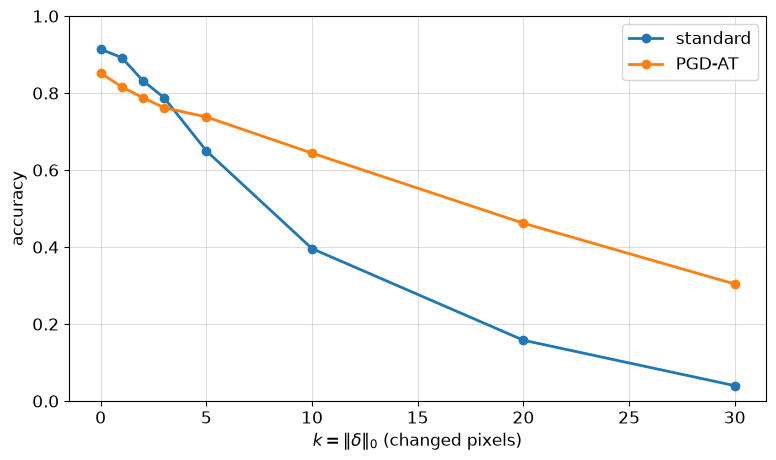

In [81]:
if '7.4' in BONUS_TASKS:
    plt.figure(figsize=(9, 5))
    for name, accs in l0_curves.items():
        plt.plot(ks, accs, 'o-', linewidth=2, label=name)
    plt.xlabel(r'$k = \|\delta\|_0$ (changed pixels)')
    plt.ylabel('accuracy')
    plt.ylim(0, 1)
    plt.legend()
    plt.grid(True, alpha=0.4)
    plt.show()

**Вопрос.** Помогает ли робастность в $L_\infty$ против $L_0$-атаки? Почему $L_\infty$-шар радиуса $\varepsilon$ не защищает от изменения одного пикселя с 0 до 1?

Робастность в $L_\infty$ помогает против $L_0$-атаки, но не защищает полностью. Accuracy от числа изменённых пикселей $k = 0, 1, 2, 3, 5, 10, 20, 30$: у стандартной модели 0.914, 0.892, 0.832, 0.788, 0.650, 0.396, 0.158, 0.040; у PGD-AT 0.852, 0.816, 0.788, 0.762, 0.738, 0.644, 0.462, 0.304. При малых $k$ (0–3) стандартная модель ещё выше (из-за более высокой clean accuracy), кривые пересекаются около $k = 3$–5, а дальше PGD-AT заметно лучше: при $k = 10$ на 25 п.п. (0.644 против 0.396), при $k = 30$ на 26 п.п. (0.304 против 0.040). Но падение у неё тоже идёт (с 0.852 до 0.304), то есть защита частичная. $L_\infty$-шар радиуса $\varepsilon = 0.1$ не защищает от изменения одного пикселя с 0 до 1, потому что такой шар разрешает менять каждый пиксель не более чем на 0.1, а $L_0$-атака меняет один пиксель на величину до 1, то есть в 10 раз больше $\varepsilon$: такие возмущения лежат вне шара, на котором тренировалась модель. Поэтому робастность в одной норме не переносится автоматически на другую. Вывод по одной модели и 500 картинкам.

## 7.5 Catastrophic overfitting (1 балл)

Включается через `'7.5'` в `BONUS_TASKS`; нужны функции из 6.1 и 6.2. Обучите две дополнительные модели с готовыми FGSM и FGSM-RS при `EPS_CO=0.2`. FGSM-RS начинает из случайной точки, делает один шаг размера $1.25\varepsilon$ и проецируется обратно в допустимое множество.

В работе [Wong et al., 2020](https://arxiv.org/pdf/2001.03994) описано catastrophic overfitting: PGD accuracy резко падает, хотя FGSM accuracy остаётся высокой. Random start может помочь, но ни возникновение эффекта за наш бюджет, ни его устранение не гарантированы.

Код обучения и графика дан; баллы — за диагностику и объяснение. Не меняйте эпохи или радиус только ради получения «нужной картинки». Если добавите контрольный опыт, запишите его настройки отдельно.

**Оценивание:** код — 0; эксперимент — 0.5; объяснение — 0.5 балла.

In [82]:
if '7.5' in BONUS_TASKS:
    EPS_CO = 0.2
    co_history = {}
    for name in ['FGSM', 'FGSM-RS']:
        print(name)
        set_seed(0)
        robust[f'{name}, eps={EPS_CO}'] = SmallCNN()
        co_history[name] = adversarial_train(robust[f'{name}, eps={EPS_CO}'], EPS_CO, TRAIN_ATTACKS[name])

FGSM
epoch 1: clean 0.674 | FGSM 0.669 | PGD 0.037
epoch 2: clean 0.474 | FGSM 0.887 | PGD 0.005
epoch 3: clean 0.348 | FGSM 0.963 | PGD 0.001
epoch 4: clean 0.378 | FGSM 0.968 | PGD 0.000
epoch 5: clean 0.408 | FGSM 0.982 | PGD 0.000
FGSM-RS
epoch 1: clean 0.740 | FGSM 0.583 | PGD 0.332
epoch 2: clean 0.802 | FGSM 0.673 | PGD 0.414
epoch 3: clean 0.797 | FGSM 0.693 | PGD 0.443
epoch 4: clean 0.795 | FGSM 0.722 | PGD 0.431
epoch 5: clean 0.807 | FGSM 0.731 | PGD 0.455


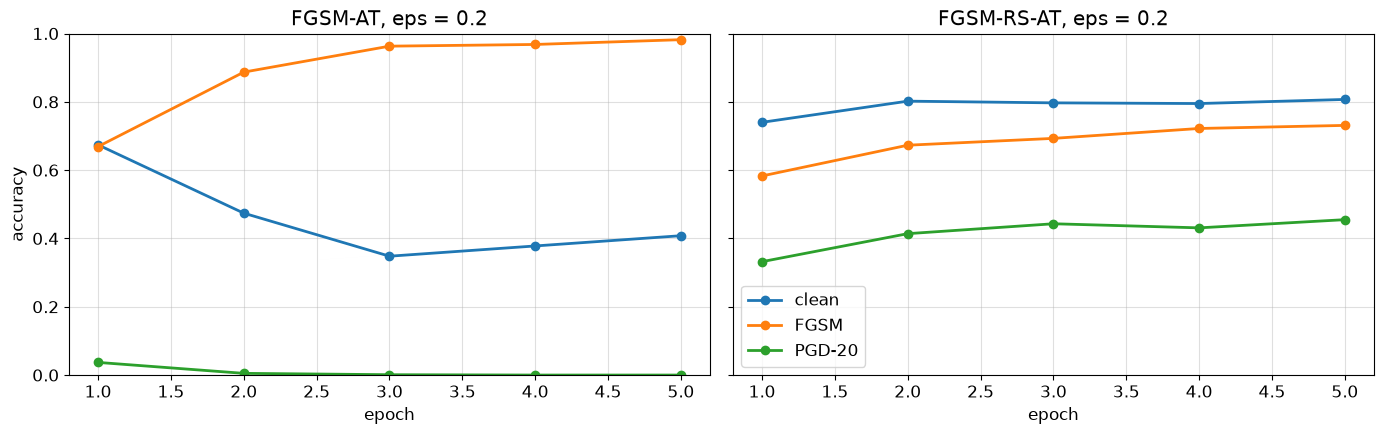

In [83]:
if '7.5' in BONUS_TASKS:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    for ax, (name, hist) in zip(axes, co_history.items()):
        epochs_axis = range(1, len(hist['clean']) + 1)
        for key, label in [('clean', 'clean'), ('fgsm', 'FGSM'), ('pgd', 'PGD-20')]:
            ax.plot(epochs_axis, hist[key], 'o-', linewidth=2, label=label)
        ax.set_title(f'{name}-AT, eps = {EPS_CO}')
        ax.set_xlabel('epoch')
        ax.grid(True, alpha=0.4)
    axes[0].set_ylabel('accuracy')
    axes[0].set_ylim(0, 1)
    axes[1].legend()
    plt.tight_layout()
    plt.show()

In [84]:
if '7.5' in BONUS_TASKS:
    co_checks = {name: sanity_checks(robust[f'{name}, eps={EPS_CO}'], XF_test[:N_SANITY], YF_test[:N_SANITY], EPS_CO)
                 for name in ['FGSM', 'FGSM-RS']}
    print(co_checks)

{'FGSM': {'fgsm': 0.375, 'pgd20': 0.0, 'pgd100_x5': 0.0, 'eps_1': 0.0}, 'FGSM-RS': {'fgsm': 0.72265625, 'pgd20': 0.45703125, 'pgd100_x5': 0.40625, 'eps_1': 0.0}}


**Вопрос.** Был ли резкий спад PGD accuracy и на какой эпохе? Изменил ли картину random start? Сопоставьте динамику FGSM/PGD и результаты усиленной атаки. Если catastrophic overfitting не наблюдается, укажите это и предложите одну проверяемую гипотезу о том, от чего он мог бы зависеть.

У обычной FGSM-AT PGD accuracy обваливается уже к концу первой эпохи: 0.037 после 1-й эпохи, затем 0.005, 0.001, 0.000, 0.000; точный момент спада внутри первой эпохи по нашим замерам (раз в эпоху) не виден. При этом FGSM accuracy растёт с 0.669 до 0.982, а clean accuracy падает с 0.674 до 0.348 (эпоха 3) и остаётся низкой (0.408 на эпохе 5). Уже со 2-й эпохи FGSM accuracy (0.887) выше clean accuracy (0.474): одношаговая атака «помогает» модели, и ответы на атакованных картинках верны чаще, чем на чистых. Это признак catastrophic overfitting: модель подстроилась под сам одношаговый шаг, но против многошаговой атаки не защищена. Усиленные проверки это подтверждают: в `co_checks` у FGSM-модели pgd20 = 0.000 и pgd100_x5 = 0.000, а fgsm = 0.375 (там clean-ошибки считаются ошибками, и значение близко к clean accuracy 0.408), то есть FGSM accuracy 0.982 из графика была завышена. Random start изменил картину: у FGSM-RS резкого спада нет, PGD-20 растёт 0.332 → 0.414 → 0.443 → 0.431 → 0.455, clean держится около 0.80 (0.807 на эпохе 5), а в `co_checks` pgd20 = 0.457 и pgd100_x5 = 0.406 (на $\varepsilon = 1$ ноль, как и должно быть). Вывод по одному seed и одному $\varepsilon = 0.2$: в нашем протоколе random start устранил эффект, но это не гарантировано в общем случае.